# Arroyo Capital: inversion en cine

Ethan Schcolnik y Nicolas Gomez

# Etapa 1: limpieza de los datos

## 1.1 Carga, tipos y fechas de los datos

C:\Users\nicog\AppData\Local\Temp\ipykernel_2888\373831156.py:55: MatplotlibDeprecationWarning:

The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.



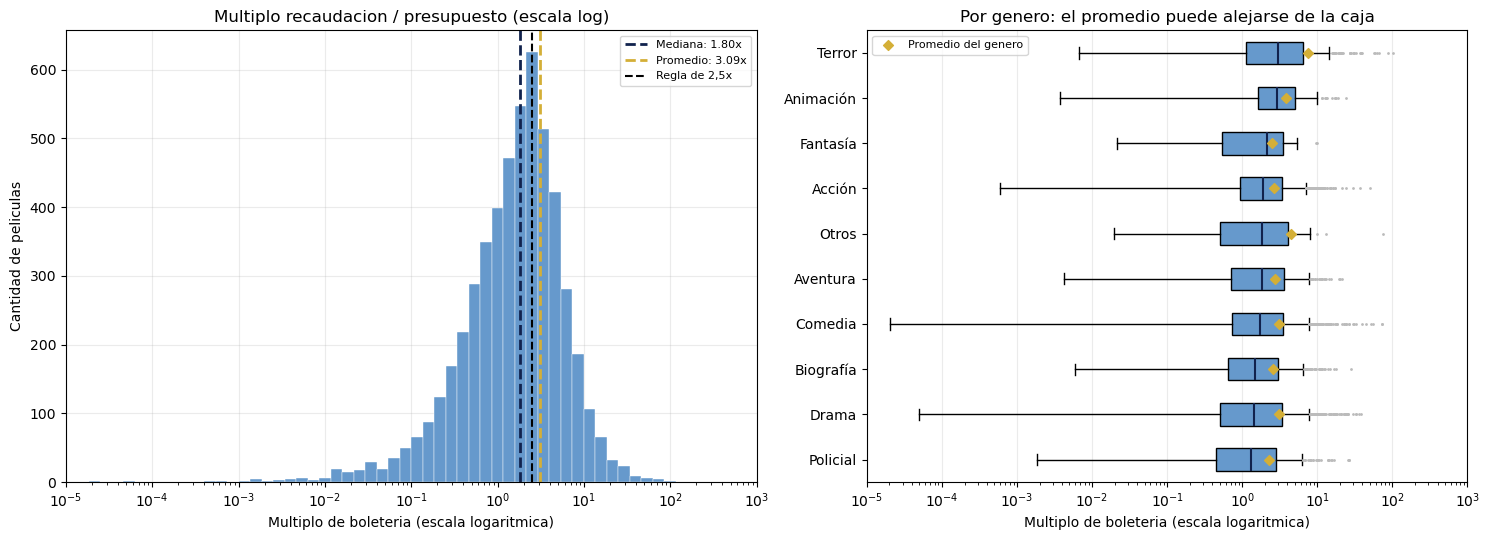

Peliculas del universo principal: 5215
Multiplo positivo mostrado: 5215 | multiplo cero excluido del grafico log: 0
Multiplo promedio y mediano: 3.09 y 1.8
ROI medio y mediano estimado (%): 3.2 y -39.9


In [262]:
CANTIDAD_BINS_MULTIPLO = 60

# La escala logaritmica solo admite multiplos estrictamente positivos.
multiplo_visual = universo_negocio.loc[
    universo_negocio.multiplo_boleteria > 0,
    ['genero', 'multiplo_boleteria']
].copy()
multiplo_visual['multiplo_boleteria'] = (
    multiplo_visual.multiplo_boleteria.astype(float))
mediana_multiplo = multiplo_visual.multiplo_boleteria.median()
media_multiplo = multiplo_visual.multiplo_boleteria.mean()
limite_min = 10 ** np.floor(np.log10(multiplo_visual.multiplo_boleteria.min()))
limite_max = 10 ** np.ceil(np.log10(multiplo_visual.multiplo_boleteria.max()))
bins_multiplo = np.logspace(
    np.log10(limite_min), np.log10(limite_max),
    CANTIDAD_BINS_MULTIPLO + 1)

# Agrupamos los generos con menos de 30 peliculas en "Otros".
generos_box = multiplo_visual.genero.value_counts()
generos_box = generos_box.loc[
    generos_box >= MIN_PELICULAS_COMPARABLES].index
multiplo_visual['grupo_genero'] = multiplo_visual.genero.where(
    multiplo_visual.genero.isin(generos_box), 'Otros')
orden_generos = (multiplo_visual.groupby('grupo_genero')
                 .multiplo_boleteria.median()
                 .sort_values(ascending=False).index.tolist())
datos_por_genero = [
    multiplo_visual.loc[
        multiplo_visual.grupo_genero == genero,
        'multiplo_boleteria'].to_numpy()
    for genero in orden_generos
]
medias_genero = [valores.mean() for valores in datos_por_genero]

fig, (ax_hist, ax_box) = plt.subplots(
    1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios':[1.15, 1]})

ax_hist.hist(multiplo_visual.multiplo_boleteria, bins=bins_multiplo,
             color=AZUL_CLARO_GRAFICO, edgecolor='white', linewidth=0.3)
ax_hist.axvline(mediana_multiplo, color=AZUL_GRAFICO, linestyle='--',
                linewidth=2, label=f'Mediana: {mediana_multiplo:.2f}x')
ax_hist.axvline(media_multiplo, color=DORADO_GRAFICO, linestyle='--',
                linewidth=2, label=f'Promedio: {media_multiplo:.2f}x')
ax_hist.axvline(UMBRAL_RECUPERO, color='black', linestyle='--',
                linewidth=1.5, label='Regla de 2,5x')
ax_hist.set_xscale('log')
ax_hist.set_xlim(limite_min, limite_max)
ax_hist.set_title('Multiplo recaudacion / presupuesto (escala log)')
ax_hist.set_xlabel('Multiplo de boleteria (escala logaritmica)')
ax_hist.set_ylabel('Cantidad de peliculas')
ax_hist.legend(fontsize=8)
ax_hist.grid(alpha=0.25)
ax_hist.set_axisbelow(True)

cajas = ax_box.boxplot(
    datos_por_genero, vert=False, patch_artist=True, labels=orden_generos,
    flierprops={'marker':'.', 'markersize':2, 'markeredgecolor':GRIS_GRAFICO},
    medianprops={'color':AZUL_GRAFICO, 'linewidth':1.5})
for caja in cajas['boxes']:
    caja.set_facecolor(AZUL_CLARO_GRAFICO)
ax_box.scatter(medias_genero, np.arange(1, len(orden_generos) + 1),
               marker='D', s=25, color=DORADO_GRAFICO,
               zorder=3, label='Promedio del genero')
ax_box.set_xscale('log')
ax_box.set_xlim(limite_min, limite_max)
ax_box.invert_yaxis()
ax_box.set_title('Por genero: el promedio puede alejarse de la caja')
ax_box.set_xlabel('Multiplo de boleteria (escala logaritmica)')
ax_box.legend(fontsize=8)
ax_box.grid(axis='x', alpha=0.25)
ax_box.set_axisbelow(True)

fig.tight_layout()
fig.savefig(carpeta_salidas / '52_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

print('Peliculas del universo principal:', len(universo_negocio))
print('Multiplo positivo mostrado:', len(multiplo_visual),
      '| multiplo cero excluido del grafico log:',
      len(universo_negocio) - len(multiplo_visual))
print('Multiplo promedio y mediano:',
      round(media_multiplo, 2), 'y', round(mediana_multiplo, 2))
print('ROI medio y mediano estimado (%):',
      round(universo_negocio.roi_pct.mean(), 1), 'y',
      round(universo_negocio.roi_pct.median(), 1))

**Tipos de datos.** Al cargar los archivos indicamos qué columnas son números y cuáles son texto. Usamos `Int64` para los identificadores y años, `Float64` para las medidas e importes, y `string` para los nombres y categorías. Estos tipos admiten valores faltantes, que revisaremos en las secciones siguientes. En el archivo de IPC también declaramos el año como entero y el índice como número decimal.

**Fechas de estreno.** La columna `fecha_estreno` contiene dos formatos: 6.564 registros en `AAAA-MM-DD` (por ejemplo, `2010-07-01`) y 1.176 en `DD/MM/AAAA` (por ejemplo, `16/11/1988`). Por eso se carga primero como texto y se convierte cada grupo con su formato explícito. Así evitamos intercambiar el día y el mes en fechas ambiguas. Luego la columna queda como `datetime64[ns]`, apta para comparar años y analizar la evolución temporal. La comprobación final muestra que las 7.740 fechas se convirtieron sin generar faltantes.

## 1.2 Dimensiones, tipos, categorias y descripcion numerica


In [263]:
print('Tamaño de cada archivo (filas, columnas):')
print('Peliculas:', peliculas.shape, '| IPC:', ipc.shape)
print('Peliculas: primeras cinco filas de ejemplo')
display(peliculas.head())
print('IPC: primeros cinco años y sus indices de precios')
display(ipc.head())
print('Peliculas: tipo de dato de cada columna')
display(peliculas.dtypes.astype(str).rename('tipo').to_frame())
print('IPC: tipo de dato de cada columna')
display(ipc.dtypes.astype(str).rename('tipo').to_frame())

categoricas = ['genero', 'clasificacion', 'pais_origen', 'es_secuela',
               'director', 'guionista', 'protagonista', 'productora']
print('Valores diferentes por columna; los faltantes cuentan como un solo valor')
display(peliculas[categoricas].nunique(dropna=False)
        .rename('categorias_distintas').to_frame())

continuas = ['duracion_minutos', 'puntaje_imdb', 'cantidad_votos',
             'presupuesto_usd', 'recaudacion_mundial_usd']
print('Variables numericas: cantidad, media, dispersion, minimo, cuartiles y maximo')
display(peliculas[continuas].describe().T.round(2))

Tamaño de cada archivo (filas, columnas):
Peliculas: (7740, 17) | IPC: (41, 2)
Peliculas: primeras cinco filas de ejemplo


,id_pelicula,titulo,anio_estreno,fecha_estreno,genero,clasificacion,pais_origen,es_secuela,director,guionista,protagonista,productora,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd
0,15834,Hatchet II,2010,2010-07-01,Acción,Mayores de 17,Estados Unidos,Si,Adam Green,Adam Green,Danielle Harris,ArieScope Pictures,85.0,5.5,13000.0,800000.0,156190.0
1,10992,Shanghai Surprise,1986,1986-08-29,Aventura,Mayores de 13,UK,No,Jim Goddard,John Kohn,Sean Penn,HandMade Films,97.0,3.2,5000.0,17000000.0,2315683.0
2,15201,Mr. Magorium's Wonder Emporium,2007,2007-11-16,Comedia,Apta todo publico,Estados Unidos,No,Zach Helm,Zach Helm,Natalie Portman,Mandate Pictures,93.0,6.2,44000.0,65000000.0,69474661.0
3,13042,Celtic Pride,1996,1996-04-19,Comedia,Mayores de 13,Estados Unidos,No,Tom DeCerchio,Judd Apatow,Damon Wayans,Caravan Pictures,91.0,5.3,9600.0,<NA>,9255027.0
4,11961,Kafka,1991,1991-11-15,Drama,Mayores de 13,Francia,No,Steven Soderbergh,Lem Dobbs,Jeremy Irons,Baltimore Pictures,98.0,6.9,9600.0,11000000.0,1059071.0


IPC: primeros cinco años y sus indices de precios


,anio,ipc_eeuu
0,1980,82.4
1,1981,90.9
2,1982,96.5
3,1983,99.6
4,1984,103.9


Peliculas: tipo de dato de cada columna


,tipo
id_pelicula,Int64
titulo,string
anio_estreno,Int64
fecha_estreno,datetime64[ns]
genero,string
clasificacion,string
pais_origen,string
es_secuela,string
director,string
guionista,string


... (2 outputs left out)

Valores diferentes por columna; los faltantes cuentan como un solo valor


,categorias_distintas
genero,25
clasificacion,11
pais_origen,65
es_secuela,2
director,2949
guionista,4536
protagonista,2815
productora,2745


Variables numericas: cantidad, media, dispersion, minimo, cuartiles y maximo


,count,mean,std,min,25%,50%,75%,max
duracion_minutos,7736.0,108.83,44.86,0.0,95.0,104.0,116.0,999.0
puntaje_imdb,7737.0,6.37,1.03,0.0,5.8,6.5,7.1,9.3
cantidad_votos,7737.0,88122.35,163333.63,7.0,9100.0,33000.0,93000.0,2400000.0
presupuesto_usd,5551.0,35000792.4,41215579.81,-1.0,10000000.0,20000000.0,43000000.0,356000000.0
recaudacion_mundial_usd,7549.0,78600686.19,168497298.56,-622674139.0,4515258.0,20240502.0,76019048.0,2847246203.0


- **Primeras filas y tipos:** sirven para comprobar que los archivos se cargaron bien y que cada columna tiene el tipo esperado.
- **Valores diferentes:** cuenta nombres o etiquetas únicos por columna; los faltantes cuentan como un único valor. Directores y productoras tienen muchos valores porque identifican personas y empresas.
- **Resumen numérico:** `count` cuenta datos presentes; media, desviación, cuartiles y extremos describen su distribución. Los valores imposibles se revisan en 1.5.

## 1.3 Filas duplicadas y peliculas repetidas


In [264]:
ID_ADICIONAL_INICIO = 90001
ID_ADICIONAL_FIN = 90014

duplicada_exacta = peliculas.duplicated()
sin_exactas = peliculas.drop_duplicates().copy()
ids_conflictivos = sin_exactas.duplicated(subset='id_pelicula').sum()

repetida_pelicula = sin_exactas.duplicated(
    subset=['titulo', 'anio_estreno'], keep=False)
peliculas_repetidas = sin_exactas.loc[repetida_pelicula].sort_values(
    ['titulo', 'id_pelicula'])
pares_repetidos = peliculas_repetidas[
    ['titulo', 'anio_estreno']].drop_duplicates()
coinciden_otros_datos = peliculas_repetidas[
    [columna for columna in peliculas_repetidas.columns
     if columna not in ['id_pelicula', 'presupuesto_usd']]
].duplicated(keep=False)

print('Copias exactas (todas las columnas iguales):', duplicada_exacta.sum(),
      f'({duplicada_exacta.mean():.2%} de la base original)')
print('ID usados en dos filas diferentes:', ids_conflictivos)
print('Peliculas cargadas dos veces:', len(pares_repetidos),
      '| cada una tiene 2 filas, en total:', len(peliculas_repetidas), 'filas')
print('De esas filas, iguales excepto por ID y presupuesto:',
      coinciden_otros_datos.sum(), 'de', len(peliculas_repetidas))
print('Los dos ID y presupuestos de cada pelicula repetida:')
display(peliculas_repetidas[
    ['id_pelicula', 'titulo', 'anio_estreno', 'presupuesto_usd']])

version_adicional = (repetida_pelicula
                     & sin_exactas.id_pelicula.between(
                         ID_ADICIONAL_INICIO, ID_ADICIONAL_FIN))
datos = sin_exactas.loc[~version_adicional].copy()

print('Segunda version retirada de cada pelicula (ID 90001-90014):',
      version_adicional.sum())
print('Filas: originales', len(peliculas),
      '| sin copias exactas', len(sin_exactas),
      '| una por pelicula', len(datos))
print('Porcentaje de filas retiradas en total:',
      f'{(len(peliculas) - len(datos)) / len(peliculas):.2%}')
print('Peliculas que aun figuran dos veces:',
      datos.duplicated(subset=['titulo', 'anio_estreno']).sum())

Copias exactas (todas las columnas iguales): 58 (0.75% de la base original)
ID usados en dos filas diferentes: 0
Peliculas cargadas dos veces: 14 | cada una tiene 2 filas, en total: 28 filas
De esas filas, iguales excepto por ID y presupuesto: 28 de 28
Los dos ID y presupuestos de cada pelicula repetida:


,id_pelicula,titulo,anio_estreno,presupuesto_usd
1970,12898,Bio-Dome,1996,15000000.0
2653,90001,Bio-Dome,1996,19697118.0
2212,13101,Breakdown,1997,36000000.0
1747,90004,Breakdown,1997,31901667.0
5906,16378,Cloudy with a Chance of Meatballs 2,2013,78000000.0
3074,90008,Cloudy with a Chance of Meatballs 2,2013,93580153.0
6101,13883,Enemy at the Gates,2001,68000000.0
5510,90011,Enemy at the Gates,2001,43107007.0
5343,12897,Executive Decision,1996,55000000.0
6287,90002,Executive Decision,1996,59619028.0


Segunda version retirada de cada pelicula (ID 90001-90014): 14
Filas: originales 7740 | sin copias exactas 7682 | una por pelicula 7668
Porcentaje de filas retiradas en total: 0.93%
Peliculas que aun figuran dos veces: 0


- **58 copias exactas:** filas idénticas en todas las columnas; se eliminan.
- **0 ID en conflicto:** ningún ID identifica dos registros diferentes.
- **14 películas duplicadas:** cada una ocupa dos filas, por eso hay 28 filas en la tabla. Por ejemplo, *Bio-Dome* (1996) figura con los ID 12898 y 90001 y con dos presupuestos distintos. El resto de sus datos coincide.
- **Decisión:** conservamos una versión por película y retiramos las 14 filas con ID 90001 a 90014. Más adelante evaluamos cuánto influye esta elección.

## 1.4 Faltantes por columna y ejemplos filtrados


In [265]:
faltantes_originales = pd.DataFrame({
    'n_faltantes':datos.isna().sum(),
    'porcentaje':(100*datos.isna().mean()).round(2)
}).sort_values('n_faltantes',ascending=False)

display(faltantes_originales)

# Mostramos ejemplos de las filas filtradas por las que no tienen presupuesto.
display(datos.loc[datos.presupuesto_usd.isna(),
                  ['id_pelicula','titulo','anio_estreno','genero','presupuesto_usd']]
        .head(6))

,n_faltantes,porcentaje
presupuesto_usd,2171,28.31
recaudacion_mundial_usd,189,2.46
clasificacion,77,1.00
productora,15,0.20
duracion_minutos,4,0.05
cantidad_votos,3,0.04
puntaje_imdb,3,0.04
pais_origen,3,0.04
guionista,3,0.04
protagonista,1,0.01


,id_pelicula,titulo,anio_estreno,genero,presupuesto_usd
3,13042,Celtic Pride,1996,Comedia,<NA>
5,11435,"Distant Voices, Still Lives",1988,Drama,<NA>
7,10739,The Holcroft Covenant,1985,Acción,<NA>
8,12429,Silent Tongue,1993,Drama,<NA>
11,11791,An Angel at My Table,1990,Biografía,<NA>
12,11681,Nikita,1990,Acción,<NA>


- **Primera tabla:** `n_faltantes` cuenta celdas vacías por columna; `porcentaje` indica qué parte de las 7.668 películas representan. Es el estado después de quitar duplicados y antes de corregir valores imposibles.
- **Segunda tabla:** muestra solo seis ejemplos de películas sin presupuesto; no son todos los casos. En 1.9 vemos si estos faltantes se concentran en ciertos grupos.

## 1.5 Valores imposibles y decisiones de limpieza


In [266]:
DURACION_NO_INFORMADA = 999
DURACIONES_INVALIDAS = [0, DURACION_NO_INFORMADA]
PUNTAJE_IMDB_MIN = 1
PUNTAJE_IMDB_MAX = 10
ANIO_INICIAL_DATOS = 1980
ANIO_FINAL_DATOS = 2020

datos_sin_corregir = datos.copy()
reglas = {
    'presupuesto_usd': datos.presupuesto_usd <= 0,
    'duracion_minutos': datos.duracion_minutos.isin(DURACIONES_INVALIDAS),
    'puntaje_imdb': (~datos.puntaje_imdb.between(
        PUNTAJE_IMDB_MIN, PUNTAJE_IMDB_MAX) & datos.puntaje_imdb.notna()),
    'cantidad_votos': datos.cantidad_votos <= 0,
}

filas_cambios = []
for columna, mascara in reglas.items():
    antes_pct = 100 * datos[columna].isna().mean()
    afectados = int(mascara.sum())
    datos.loc[mascara, columna] = np.nan
    filas_cambios.append({
        'columna': columna, 'valores_invalidados': afectados,
        'base_afectada_pct': round(100 * afectados / len(datos), 2),
        'faltantes_antes_pct': round(antes_pct, 2),
        'faltantes_despues_pct': round(100 * datos[columna].isna().mean(), 2),
    })

# Las recaudaciones negativas se contrastaron con fuentes externas: nueve
# importes corresponden al mundial con signo invertido y dos al domestico.
recaudaciones_negativas = datos.recaudacion_mundial_usd < 0
datos.loc[recaudaciones_negativas, 'recaudacion_mundial_usd'] = (
    datos.loc[recaudaciones_negativas, 'recaudacion_mundial_usd'].abs())
datos.loc[datos.titulo == 'Planes, Trains & Automobiles',
          'recaudacion_mundial_usd'] = 49530552
datos.loc[datos.titulo == 'The Long Day Closes',
          'recaudacion_mundial_usd'] = 22885

print('Valores imposibles invalidados:')
display(pd.DataFrame(filas_cambios))
print('Recaudaciones negativas corregidas:',
      int(recaudaciones_negativas.sum()))
print('Negativos restantes:',
      int((datos.recaudacion_mundial_usd < 0).sum()))
print('Peliculas antes y despues:', len(datos_sin_corregir), len(datos))
print('Presupuestos en cero:',
      int((datos_sin_corregir.presupuesto_usd == 0).sum()),
      '| negativos:', int((datos_sin_corregir.presupuesto_usd < 0).sum()))
print('Duraciones de 0 o 999:',
      int(datos_sin_corregir.duracion_minutos.isin(DURACIONES_INVALIDAS).sum()))
print('Puntajes IMDb fuera de 1-10:',
      int((~datos_sin_corregir.puntaje_imdb.between(1, 10)
           & datos_sin_corregir.puntaje_imdb.notna()).sum()))
print('Años fuera de 1980-2020:',
      int((~datos_sin_corregir.anio_estreno.between(
          ANIO_INICIAL_DATOS, ANIO_FINAL_DATOS)).sum()))

Valores imposibles invalidados:


,columna,valores_invalidados,base_afectada_pct,faltantes_antes_pct,faltantes_despues_pct
0,presupuesto_usd,48,0.63,28.31,28.94
1,duracion_minutos,34,0.44,0.05,0.50
2,puntaje_imdb,22,0.29,0.04,0.33
3,cantidad_votos,0,0.00,0.04,0.04


Recaudaciones negativas corregidas: 11
Negativos restantes: 0
Peliculas antes y despues: 7668 7668
Presupuestos en cero: 26 | negativos: 22
Duraciones de 0 o 999: 34
Puntajes IMDb fuera de 1-10: 22
Años fuera de 1980-2020: 0


- **Tabla de cambios:** `valores_invalidados` cuenta datos imposibles reemplazados por faltantes; `base_afectada_pct` mide su peso sobre todas las películas. `faltantes_antes_pct` y `faltantes_despues_pct` muestran cómo cambia cada columna.
- **¿Qué corregimos?** Si un valor no sirve para el análisis, lo dejamos como faltante (`NaN`):
  - Presupuesto de **0 o negativo**: no permite calcular un retorno válido.
  - Duración de **0 minutos**: imposible; **999 minutos**: se interpreta como valor de relleno.
  - Puntaje IMDb **menor que 1 o mayor que 10**: está fuera de la escala.
  - Cantidad de votos de **0 o negativa**: no se toma como un conteo válido.
- **Qué se conserva:** solo se vacía el valor incorrecto; la fila de la película permanece para los análisis que puedan usar sus otros datos.
- **Recaudación:** los 11 importes negativos se revisaron por separado; se corrigió el signo en nueve y se sustituyeron dos importes domésticos por los mundiales verificados.

## 1.6 Presupuestos con escala dudosa


In [267]:
PRESUPUESTO_BAJO_MAX = 1_000_000
RECAUDACION_ALTA_MIN = 20_000_000
MULTIPLO_EXTREMO_MIN = 100
MULTIPLO_MODERADO_MAX = 20

# Cociente diagnostico de dos columnas originales; todavia no es el ROI de la etapa 2.
datos['recaudacion_sobre_presupuesto'] = (
    datos.recaudacion_mundial_usd / datos.presupuesto_usd)

datos['escala_dudosa'] = (
    (datos.presupuesto_usd > 0)
    & (datos.presupuesto_usd < PRESUPUESTO_BAJO_MAX)
    & (datos.recaudacion_mundial_usd >= RECAUDACION_ALTA_MIN)
    & (datos.recaudacion_sobre_presupuesto > MULTIPLO_EXTREMO_MIN)
)

print('Candidatas a escala dudosa:',datos.escala_dudosa.sum(),
      f'({datos.escala_dudosa.mean():.2%} de la base depurada)')

# Primera tabla: presupuestos pequenos con recaudacion muy alta.
print('Presupuestos pequeños con recaudacion muy alta:')
display(datos.loc[datos.escala_dudosa,
                  ['titulo','anio_estreno','presupuesto_usd',
                   'recaudacion_mundial_usd','recaudacion_sobre_presupuesto']]
        .sort_values('recaudacion_sobre_presupuesto',ascending=False)
        .head(8).round(1))

# Segunda tabla: presupuestos pequenos con una relacion mas moderada.
print('Presupuestos pequeños con una relacion mas moderada:')
display(datos.loc[(datos.presupuesto_usd > 0)
                  & (datos.presupuesto_usd < PRESUPUESTO_BAJO_MAX)
                  & datos.recaudacion_sobre_presupuesto.between(
                      0, MULTIPLO_MODERADO_MAX),
                  ['titulo','presupuesto_usd','recaudacion_mundial_usd',
                   'recaudacion_sobre_presupuesto']].head(6).round(1))

Candidatas a escala dudosa: 31 (0.43% de la base depurada)
Presupuestos pequeños con recaudacion muy alta:


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd,recaudacion_sobre_presupuesto
264,Platoon,1986,6000.0,138545632.0,23090.9
4439,Bean,1997,18000.0,251212670.0,13956.3
5927,Paranormal Activity,2007,15000.0,193355800.0,12890.4
1882,"Good Night, and Good Luck.",2005,7000.0,54641191.0,7805.9
3336,Sex and the City,2008,65000.0,418765519.0,6442.5
448,Guardians of the Galaxy Vol. 2,2017,200000.0,863756051.0,4318.8
1648,The Blair Witch Project,1999,60000.0,248639099.0,4144.0
283,21 & Over,2013,13000.0,48065672.0,3697.4


Presupuestos pequeños con una relacion mas moderada:


,titulo,presupuesto_usd,recaudacion_mundial_usd,recaudacion_sobre_presupuesto
0,Hatchet II,800000.0,156190.0,0.2
6,Re-Animator,900000.0,2023414.0,2.2
70,Welcome to the Dollhouse,800000.0,4569019.0,5.7
100,The Canyons,250000.0,270185.0,1.1
217,Living in Oblivion,500000.0,1111790.0,2.2
252,The Brother from Another Planet,350000.0,3677209.0,10.5


- **Cociente:** `recaudacion_sobre_presupuesto` divide la boletería mundial por el presupuesto. Sirve para detectar cifras sospechosas; todavía no es el retorno del inversor.
- **Primera tabla:** reúne presupuestos menores a USD 1 millón con recaudación de al menos USD 20 millones y cociente mayor a 100. Algunos podrían estar anotados en *miles* en vez de dólares: *Platoon* figura con USD 6.000 en la base, frente a [USD 6 millones](https://www.the-numbers.com/movie/Platoon); *Guardians of the Galaxy Vol. 2* figura con USD 200.000, frente a [USD 200 millones](https://www.the-numbers.com/movie/Guardians-of-the-Galaxy-Vol-2). En esos ejemplos falta un factor de 1.000.
- **No todos son errores:** *Paranormal Activity* figura con USD 15.000 y [Paramount también la describe como una película de USD 15.000](https://ir.paramount.com/news-releases/news-release-details/paramount-pictures-paranormal-activity-soars-past-100-million/).
- **Segunda tabla y decisión:** muestra presupuestos pequeños con cocientes de hasta 20 para comparar. Marcamos los 31 casos sospechosos; cada uno debe verificarse antes de corregirlo, porque multiplicar todos por 1.000 alteraría presupuestos reales.

## 1.7 Normalizar categorias


In [268]:
categorias_clave = ['genero', 'clasificacion', 'pais_origen', 'es_secuela',
                    'productora']
antes_categorias = datos[categorias_clave].copy()

mapa_genero = {
    'accion': 'Acción', 'biografia': 'Biografía',
    'animacion': 'Animación', 'ciencia ficcion': 'Ciencia ficción',
}
datos['genero'] = (datos.genero.str.strip().str.lower()
                   .replace(mapa_genero).str.capitalize())

mapa_clasificacion = {
    'atp': 'ATP', 'apta todo publico': 'ATP',
    'supervision parental': 'Supervisión parental',
    'mayores de 13': 'Mayores de 13',
    'mayores de 17': 'Mayores de 17',
    'solo adultos': 'Solo adultos',
    'sin clasificar': 'Sin clasificar',
}
datos['clasificacion'] = (datos.clasificacion.str.strip().str.lower()
                           .replace(mapa_clasificacion).fillna('No informado'))

datos['pais_origen'] = datos.pais_origen.str.strip().replace({
    'EE.UU.': 'Estados Unidos', 'UK': 'Reino Unido',
    'Canada': 'Canadá', 'Japon': 'Japón', 'Espania': 'España',
    'Mexico': 'México', 'Romania': 'Rumanía', 'Libya': 'Libia',
})
# Tres países faltantes fueron contrastados con fuentes externas.
titulos_eeuu = ['Clinton Road', 'Saw: The Final Chapter', 'The Wolfman']
datos.loc[datos.titulo.isin(titulos_eeuu) & datos.pais_origen.isna(),
          'pais_origen'] = 'Estados Unidos'

datos['es_secuela'] = datos.es_secuela.str.strip()
datos['productora'] = datos.productora.str.strip().str.title()

filas_categorias = []
for columna in categorias_clave:
    modificadas = (antes_categorias[columna].fillna('') !=
                   datos[columna].fillna('')).sum()
    filas_categorias.append({
        'columna': columna,
        'categorias_antes': antes_categorias[columna].nunique(dropna=False),
        'filas_modificadas': int(modificadas),
        'base_afectada_pct': round(100 * modificadas / len(datos), 2),
        'no_nulos_antes_pct': round(100 * antes_categorias[columna].notna().mean(), 2),
        'no_nulos_despues_pct': round(100 * datos[columna].notna().mean(), 2),
        'categorias_despues': datos[columna].nunique(dropna=False),
    })
print('Cambios en las variables categoricas:')
display(pd.DataFrame(filas_categorias))

Cambios en las variables categoricas:


,columna,categorias_antes,filas_modificadas,base_afectada_pct,no_nulos_antes_pct,no_nulos_despues_pct,categorias_despues
0,genero,25,696,9.08,100.00,100.0,18
1,clasificacion,11,2064,26.92,99.00,100.0,8
2,pais_origen,65,769,10.03,99.96,100.0,58
3,es_secuela,2,0,0.00,100.00,100.0,2
4,productora,2745,2060,26.86,99.80,99.8,2384


- **Tabla de cambios:** `categorias_antes` y `categorias_despues` cuentan nombres distintos por columna; `filas_modificadas` indica cuántos registros cambiaron. `base_afectada_pct` expresa ese cambio como porcentaje de las películas.
- **Datos presentes:** `no_nulos_antes_pct` y `no_nulos_despues_pct` indican qué porcentaje tiene un valor cargado. En clasificación, `No informado` sigue significando dato desconocido aunque ya no figure como nulo.
- **Decisiones:** unificamos variantes de género, clasificación y país. Se completaron tres países tras consultar fuentes externas; para *Saw: The Final Chapter* se usa Estados Unidos como país principal.

## 1.8 Cobertura temporal


In [269]:
ANIO_COBERTURA_REGULAR_INICIO = 1985
ANIO_COBERTURA_REGULAR_FIN = 2019

cobertura = datos.groupby('anio_estreno').agg(
    peliculas=('id_pelicula','size'),
    con_presupuesto=('presupuesto_usd','count'),
    con_recaudacion=('recaudacion_mundial_usd','count')).reset_index()
cobertura['sin_recaudacion_pct'] = (
    100*(1-cobertura.con_recaudacion/cobertura.peliculas)).round(1)

display(pd.concat([cobertura.head(6),cobertura.iloc[-6:]]))

print('Años presentes:',cobertura.anio_estreno.nunique(),
      '| rango:',cobertura.anio_estreno.min(),'-',cobertura.anio_estreno.max())
print(f'Peliculas por año entre {ANIO_COBERTURA_REGULAR_INICIO} y '
      f'{ANIO_COBERTURA_REGULAR_FIN}: minimo',
      cobertura.loc[cobertura.anio_estreno.between(
          ANIO_COBERTURA_REGULAR_INICIO, ANIO_COBERTURA_REGULAR_FIN),
          'peliculas'].min(),
      'y maximo',
      cobertura.loc[cobertura.anio_estreno.between(
          ANIO_COBERTURA_REGULAR_INICIO, ANIO_COBERTURA_REGULAR_FIN),
          'peliculas'].max())

# Comprobamos si el ano declarado coincide con la fecha de estreno.
anio_distinto = ((datos.fecha_estreno.dt.year != datos.anio_estreno)
                 & datos.fecha_estreno.notna())
print('Año declarado distinto del año de fecha:',anio_distinto.sum(),
      f'({anio_distinto.mean():.1%})')
print('Años de peliculas sin IPC:',
      len(set(datos.anio_estreno)-set(ipc.anio)))

,anio_estreno,peliculas,con_presupuesto,con_recaudacion,sin_recaudacion_pct
0,1980,92,47,81,12.0
1,1981,113,68,104,8.0
2,1982,126,74,119,5.6
3,1983,144,89,128,11.1
4,1984,168,89,158,6.0
5,1985,200,98,177,11.5
35,2015,200,155,199,0.5
36,2016,200,159,200,0.0
37,2017,200,132,200,0.0
38,2018,200,141,200,0.0


Años presentes: 41 | rango: 1980 - 2020
Peliculas por año entre 1985 y 2019: minimo 200 y maximo 200
Año declarado distinto del año de fecha: 1297 (16.9%)
Años de peliculas sin IPC: 0


- **Tabla por año:** `peliculas` cuenta estrenos; `con_presupuesto` y `con_recaudacion` cuentan cuántos tienen esos importes. `sin_recaudacion_pct` es la proporción sin boletería registrada. Se muestran los primeros y últimos seis años.
- **Cobertura:** 2020 tiene muchos menos registros; no lo usamos para afirmar que la industria cayó. Algunas fechas no coinciden con `anio_estreno`; para los importes usamos el año declarado, como indica la consigna.

## 1.9 ¿Falta presupuesto al azar?


In [270]:
ANIOS_POR_DECADA = 10

# Marcamos los faltantes para comparar grupos sin borrar ni imputar filas.
datos['sin_presupuesto'] = datos.presupuesto_usd.isna()
datos['decada'] = (datos.anio_estreno // ANIOS_POR_DECADA) * ANIOS_POR_DECADA

def tabla_faltantes(columna):
    tabla = datos.groupby(columna,dropna=False).agg(
        peliculas=('id_pelicula','size'),
        sin_presupuesto_pct=('sin_presupuesto','mean')).reset_index()
    tabla['sin_presupuesto_pct'] = (100*tabla.sin_presupuesto_pct).round(1)
    return tabla.sort_values('peliculas',ascending=False)

print('Por decada:')
display(tabla_faltantes('decada'))

print('Por genero:')
display(tabla_faltantes('genero'))

print('Por pais:')
display(tabla_faltantes('pais_origen'))

sin_presupuesto = int(datos.sin_presupuesto.sum())
con_ambos = int((datos.presupuesto_usd.notna()
                 & datos.recaudacion_mundial_usd.notna()).sum())
print('Sin presupuesto:',sin_presupuesto,
      f'({sin_presupuesto/len(datos):.1%} de {len(datos)} peliculas)')
print('Con presupuesto y recaudacion para analisis futuro:',con_ambos,
      f'({con_ambos/len(datos):.1%} de la base depurada)')

Por decada:


,decada,peliculas,sin_presupuesto_pct
1,1990,2000,31.6
2,2000,2000,18.0
3,2010,2000,24.8
0,1980,1643,43.9
4,2020,25,40.0


Por genero:


,genero,peliculas,sin_presupuesto_pct
5,Comedia,2245,33.5
0,Acción,1705,17.0
7,Drama,1518,42.5
13,Policial,551,26.9
3,Biografía,443,28.9
2,Aventura,427,23.9
1,Animación,338,18.9
16,Terror,322,18.0
9,Fantasía,44,4.5
11,Misterio,20,15.0


Por pais:


,pais_origen,peliculas,sin_presupuesto_pct
16,Estados Unidos,5478,20.8
44,Reino Unido,816,40.0
19,Francia,279,62.4
8,Canadá,190,40.5
0,Alemania,117,32.5
4,Australia,92,54.3
31,Japón,81,60.5
23,India,62,85.5
29,Italia,61,68.9
15,España,47,63.8


Sin presupuesto: 2219 (28.9% de 7668 peliculas)
Con presupuesto y recaudacion para analisis futuro: 5389 (70.3% de la base depurada)


- **Tres tablas:** para cada década, género o país, `peliculas` es el tamaño del grupo y `sin_presupuesto_pct` indica qué porcentaje no tiene presupuesto.
- **Conclusión:** los faltantes se distribuyen de forma desigual; borrar todas esas películas podría sesgar las comparaciones. Se conservan en la base general y solo se excluyen de cálculos que necesitan presupuesto y recaudación.

# Etapa 2: creacion de variables

## 2.1 Presupuesto y recaudacion en dolares de 2020


In [271]:
ANIO_BASE_IPC = 2020
USD_POR_MILLON = 1_000_000

# Cada ano del IPC debe aportar un solo valor al cruce.
ipc_para_cruce = ipc.rename(columns={'anio':'anio_estreno'})
print('Años repetidos en IPC:', ipc_para_cruce.anio_estreno.duplicated().sum())

filas_antes_ipc = len(datos)
datos = datos.merge(ipc_para_cruce, on='anio_estreno', how='left')
print('Peliculas antes y despues del cruce:', filas_antes_ipc, 'y', len(datos))
print('Peliculas sin IPC:', datos.ipc_eeuu.isna().sum())

ipc_base = ipc.loc[ipc.anio == ANIO_BASE_IPC, 'ipc_eeuu'].iloc[0]
datos['factor_a_2020'] = ipc_base / datos.ipc_eeuu
datos['presupuesto_2020_usd'] = (
    datos.presupuesto_usd * datos.factor_a_2020)
datos['recaudacion_2020_usd'] = (
    datos.recaudacion_mundial_usd * datos.factor_a_2020)

print(f'IPC de referencia, año {ANIO_BASE_IPC}:', ipc_base)
print('Presupuestos disponibles antes y despues:',
      datos.presupuesto_usd.notna().sum(), 'y',
      datos.presupuesto_2020_usd.notna().sum())
print('Recaudaciones disponibles antes y despues:',
      datos.recaudacion_mundial_usd.notna().sum(), 'y',
      datos.recaudacion_2020_usd.notna().sum())

# Mostramos importes en millones para que la comparacion sea legible.
muestra_1980 = datos.loc[(datos.anio_estreno == ANIO_INICIAL_DATOS)
                        & datos.presupuesto_usd.notna()
                        & datos.recaudacion_mundial_usd.notna()].head(3).copy()
muestra_1980['presupuesto_corriente_millones'] = (
    muestra_1980.presupuesto_usd / USD_POR_MILLON)
muestra_1980['presupuesto_2020_millones'] = (
    muestra_1980.presupuesto_2020_usd / USD_POR_MILLON)
muestra_1980['recaudacion_corriente_millones'] = (
    muestra_1980.recaudacion_mundial_usd / USD_POR_MILLON)
muestra_1980['recaudacion_2020_millones'] = (
    muestra_1980.recaudacion_2020_usd / USD_POR_MILLON)

print('Ejemplos de', ANIO_INICIAL_DATOS, ': importes en millones de USD:')
display(muestra_1980[['titulo','factor_a_2020',
                     'presupuesto_corriente_millones',
                     'presupuesto_2020_millones',
                     'recaudacion_corriente_millones',
                     'recaudacion_2020_millones']].round(2))

Años repetidos en IPC: 0
Peliculas antes y despues del cruce: 7668 y 7668
Peliculas sin IPC: 0
IPC de referencia, año 2020: 258.8
Presupuestos disponibles antes y despues: 5449 y 5449
Recaudaciones disponibles antes y despues: 7479 y 7479
Ejemplos de 1980 : importes en millones de USD:


,titulo,factor_a_2020,presupuesto_corriente_millones,presupuesto_2020_millones,recaudacion_corriente_millones,recaudacion_2020_millones
167,Heaven's Gate,3.14,44.0,138.19,3.48,10.94
314,The Final Countdown,3.14,12.0,37.69,16.65,52.29
328,Stardust Memories,3.14,10.0,31.41,10.39,32.63


- **Controles iniciales:** cada año tiene un solo IPC; el cruce conserva las 7.668 películas y ninguna queda sin índice. Los conteos antes y después muestran que el ajuste no inventa importes faltantes.
- **Operación:** `factor_a_2020 = IPC de 2020 / IPC del año de estreno`. Luego, `importe en USD de 2020 = importe original × factor_a_2020`. Aplicamos la misma cuenta al presupuesto y a la recaudación.
- **Ejemplo de la tabla:** para 1980, el factor es `258,8 / 82,4 ≈ 3,14`. Un presupuesto original de 44 millones se convierte en `44 × (258,8 / 82,4) = 138,19` millones de USD de 2020. Este ajuste corrige inflación, no errores como un presupuesto cargado en miles.

## 2.2 Retorno estimado y recuperacion de la inversion


In [272]:
# Supuestos fijos del caso; se nombran como constantes, como en Clean Code.
PORCION_BOLETERIA_ESTUDIO = 0.50
MARKETING_SOBRE_PRESUPUESTO = 0.50
UMBRAL_RECUPERO = 2.5

# El mismo factor de IPC en numerador y denominador deja igual el multiplo.
datos['multiplo_boleteria'] = (
    datos.recaudacion_2020_usd / datos.presupuesto_2020_usd)
ingreso_estudio_estimado = (
    datos.recaudacion_2020_usd * PORCION_BOLETERIA_ESTUDIO)
costo_total_estimado = (
    datos.presupuesto_2020_usd * (1 + MARKETING_SOBRE_PRESUPUESTO))
datos['roi_salas_estimado'] = (
    (ingreso_estudio_estimado - costo_total_estimado) / costo_total_estimado)

# Sin las dos cifras, no asignamos un resultado de recuperacion.
con_ambos = (datos.presupuesto_2020_usd.notna()
             & datos.recaudacion_2020_usd.notna())
datos['recupero_2_5x'] = 'Sin datos'
datos.loc[con_ambos, 'recupero_2_5x'] = 'No'
datos.loc[con_ambos & (datos.multiplo_boleteria >= UMBRAL_RECUPERO),
          'recupero_2_5x'] = 'Si'

print('ROI calculable antes de revisar la escala:',
      datos.roi_salas_estimado.notna().sum(),
      f'({datos.roi_salas_estimado.notna().mean():.1%} de la base)')
print('Con escala de presupuesto dudosa entre los ROI calculables:',
      (con_ambos & datos.escala_dudosa).sum())
print('Regla 2,5× preliminar (incluye presupuestos de escala dudosa):')
display(datos.recupero_2_5x.value_counts()
        .rename_axis('recupero_2_5x').reset_index(name='peliculas'))

columnas_ejemplo = ['titulo','anio_estreno','multiplo_boleteria',
                    'roi_salas_estimado','recupero_2_5x']
ejemplos_roi = pd.concat([
    datos.loc[datos.recupero_2_5x == 'Si', columnas_ejemplo].head(2),
    datos.loc[datos.recupero_2_5x == 'No', columnas_ejemplo].head(2),
    datos.loc[datos.recupero_2_5x == 'Sin datos', columnas_ejemplo].head(2)
])
print('Ejemplos de las variables nuevas:')
display(ejemplos_roi.round(2))

ROI calculable antes de revisar la escala: 5389 (70.3% de la base)
Con escala de presupuesto dudosa entre los ROI calculables: 31
Regla 2,5× preliminar (incluye presupuestos de escala dudosa):


,recupero_2_5x,peliculas
0,No,3273
1,Sin datos,2279
2,Si,2116


Ejemplos de las variables nuevas:


,titulo,anio_estreno,multiplo_boleteria,roi_salas_estimado,recupero_2_5x
9,Another 48 Hrs.,1990,4.04,0.35,Si
10,The American,2010,3.39,0.13,Si
0,Hatchet II,2010,0.2,-0.93,No
1,Shanghai Surprise,1986,0.14,-0.95,No
3,Celtic Pride,1996,<NA>,<NA>,Sin datos
5,"Distant Voices, Still Lives",1988,<NA>,<NA>,Sin datos


- **Supuestos:** el estudio recibe el 50% de la boletería y el marketing cuesta otro 50% del presupuesto. El ROI estimado es `(ingreso del estudio - costo total) / costo total`; por ejemplo, `0,35` equivale a 35%.
- **Regla de 2,5×:** el múltiplo divide recaudación por presupuesto. La tabla cuenta películas con `Sí` (al menos 2,5×), `No` o `Sin datos` (falta algún importe). La última tabla muestra dos ejemplos de cada resultado.
- **Dos criterios distintos:** con los supuestos anteriores, el ROI llega a cero recién con 3×. Por eso una película puede cumplir 2,5× y aun así tener ROI negativo.
- **Alcance:** estos resultados son preliminares: 31 presupuestos de escala dudosa pueden inflar el ROI. Las comparaciones y la propuesta usan la base filtrada de 3.2.

## 2.3 Indicadores de riesgo para el negocio

In [273]:
# Dejamos el resultado como faltante si no hay importes para calcularlo.
datos['fracaso_2_5x'] = datos.recupero_2_5x.map(
    {'Si': False, 'No': True}).astype('boolean')
datos['perdida_roi'] = (datos.roi_salas_estimado < 0).astype('boolean')

comparables_riesgo = datos.loc[
    datos.fracaso_2_5x.notna() & datos.perdida_roi.notna()]
resumen_indicadores = pd.DataFrame({
    'indicador': ['No alcanza 2,5 veces el presupuesto', 'ROI estimado negativo'],
    'peliculas': [int(comparables_riesgo.fracaso_2_5x.sum()),
                  int(comparables_riesgo.perdida_roi.sum())],
})
resumen_indicadores['porcentaje'] = (
    100 * resumen_indicadores.peliculas / len(comparables_riesgo)).round(1)
print('Peliculas con ambos importes:', len(comparables_riesgo))
display(resumen_indicadores)
print('Cumplen 2,5 veces, pero tienen ROI negativo:',
      int((~comparables_riesgo.fracaso_2_5x
           & comparables_riesgo.perdida_roi).sum()))

Peliculas con ambos importes: 5389


,indicador,peliculas,porcentaje
0,"No alcanza 2,5 veces el presupuesto",3273,60.7
1,ROI estimado negativo,3645,67.6


Cumplen 2,5 veces, pero tienen ROI negativo: 372


- `fracaso_2_5x` marca las películas que no alcanzan la regla de 2,5 veces el presupuesto; `perdida_roi` marca las que pierden dinero bajo los supuestos de costos de 2.2.
- La tabla cuenta cuántas películas cumplen cada condición y qué porcentaje representan entre las que tienen ambos importes. Si falta presupuesto o recaudación, el indicador queda sin dato.
- Una película puede superar 2,5 veces y aun así tener ROI negativo, porque con estos costos necesita llegar a 3 veces. Los resultados siguen siendo preliminares hasta aplicar el filtro de 3.2.

# Etapa 3: analisis de negocio

## 3.1 ¿Crecio la industria?


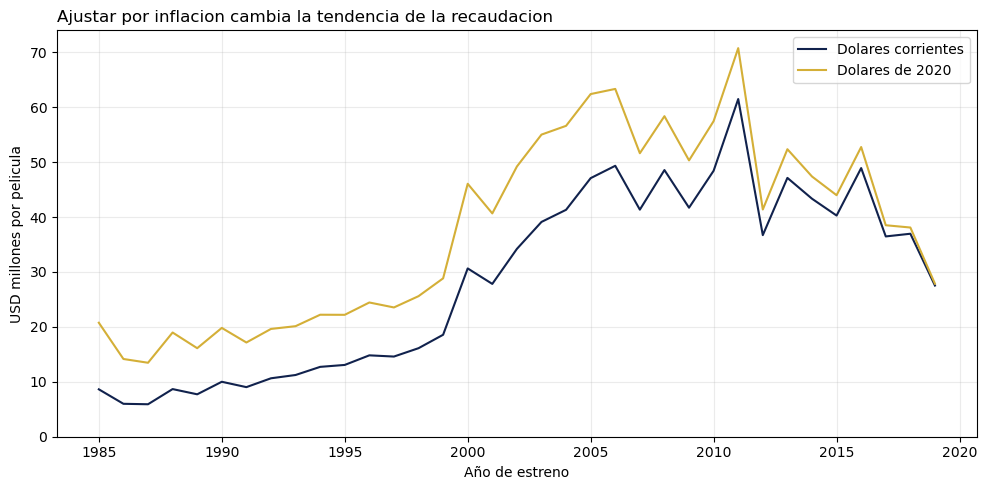

Recaudacion mediana por decada completa, en USD millones:


,decada,peliculas,nominal_mediana_millones,real_mediana_millones
0,1990,2000,12.87,22.13
1,2000,2000,40.41,53.42
2,2010,2000,41.67,45.79


Cobertura del ultimo año, excluido del grafico:


,anio_estreno,peliculas,con_recaudacion,sin_recaudacion_pct
40,2020,25,15,40.0


In [274]:
import matplotlib.pyplot as plt
import seaborn as sns

# Paleta usada en las clases: azul para la serie base y dorado para destacar.
AZUL_GRAFICO = '#11224D'
AZUL_CLARO_GRAFICO = '#6699CC'
DORADO_GRAFICO = '#D4AF37'
DECADA_COMPARACION_INICIO = 1990

evolucion = datos.groupby('anio_estreno').agg(
    peliculas=('id_pelicula','size'),
    con_recaudacion=('recaudacion_mundial_usd','count'),
    nominal_mediana=('recaudacion_mundial_usd','median'),
    real_mediana=('recaudacion_2020_usd','median')).reset_index()
evolucion['sin_recaudacion_pct'] = (
    100 * (1 - evolucion.con_recaudacion / evolucion.peliculas)).round(1)
evolucion['nominal_millones'] = evolucion.nominal_mediana / USD_POR_MILLON
evolucion['real_millones'] = evolucion.real_mediana / USD_POR_MILLON

serie_regular = evolucion.loc[evolucion.anio_estreno.between(
    ANIO_COBERTURA_REGULAR_INICIO, ANIO_COBERTURA_REGULAR_FIN)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(serie_regular.anio_estreno, serie_regular.nominal_millones,
        label='Dolares corrientes', color=AZUL_GRAFICO)
ax.plot(serie_regular.anio_estreno, serie_regular.real_millones,
        label='Dolares de 2020', color=DORADO_GRAFICO)
ax.set_title('Ajustar por inflacion cambia la tendencia de la recaudacion', loc='left')
ax.set_xlabel('Año de estreno')
ax.set_ylabel('USD millones por pelicula')
ax.set_ylim(0, None)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(carpeta_salidas / '34_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

# Comparamos decadas completas para resumir la tendencia de las dos series.
decadas_completas = datos.loc[datos.anio_estreno.between(
    DECADA_COMPARACION_INICIO, ANIO_COBERTURA_REGULAR_FIN)]
resumen_decadas = decadas_completas.groupby('decada').agg(
    peliculas=('id_pelicula','size'),
    nominal_mediana=('recaudacion_mundial_usd','median'),
    real_mediana=('recaudacion_2020_usd','median')).reset_index()
resumen_decadas['nominal_mediana_millones'] = (
    resumen_decadas.nominal_mediana / USD_POR_MILLON)
resumen_decadas['real_mediana_millones'] = (
    resumen_decadas.real_mediana / USD_POR_MILLON)

print('Recaudacion mediana por decada completa, en USD millones:')
display(resumen_decadas[
    ['decada','peliculas','nominal_mediana_millones',
     'real_mediana_millones']].round(2))
print('Cobertura del ultimo año, excluido del grafico:')
display(evolucion.loc[evolucion.anio_estreno == ANIO_BASE_IPC,
                      ['anio_estreno','peliculas','con_recaudacion',
                       'sin_recaudacion_pct']])

- **En dólares corrientes:** la recaudación mediana por película pasa de USD 12,87 millones en los 90 a 40,41 millones en los 2000 y 41,67 millones en los 2010.
- **En dólares de 2020:** pasa de 22,13 a 53,42 millones y luego baja a 45,79 millones. Hubo un aumento real de los 90 a los 2000, pero no de los 2000 a los 2010; el pequeño aumento nominal de esta última comparación se explica por la inflación.
- **Alcance:** medimos la película mediana de esta base, no la recaudación total de la industria. Excluimos 2020 porque solo tiene 25 películas y al 40% le falta recaudación.

## 3.2 ¿Cuanto rinde cada tipo de pelicula?


In [275]:
PRESUPUESTO_MIN_ANALISIS = 1_000_000
MIN_PELICULAS_COMPARABLES = 30

con_roi = datos.loc[datos.roi_salas_estimado.notna()].copy()
con_roi_hasta_2019 = con_roi.loc[
    con_roi.anio_estreno <= ANIO_COBERTURA_REGULAR_FIN].copy()
universo_negocio = con_roi_hasta_2019.loc[
    con_roi_hasta_2019.presupuesto_usd >= PRESUPUESTO_MIN_ANALISIS].copy()
universo_negocio['roi_pct'] = 100 * universo_negocio.roi_salas_estimado

print('ROI disponibles:', len(con_roi))
print('Excluidas por 2020 incompleto:',
      len(con_roi) - len(con_roi_hasta_2019))
print('Excluidas por presupuesto menor a USD 1 millon:',
      len(con_roi_hasta_2019) - len(universo_negocio),
      f'({(len(con_roi_hasta_2019) - len(universo_negocio)) / len(con_roi_hasta_2019):.1%}'
      ' de los ROI hasta 2019)')
print('Universo principal:', len(universo_negocio),
      f'({len(universo_negocio) / len(datos):.1%} de la base depurada)')
casos_dudosos_universo = int(universo_negocio.escala_dudosa.sum())
print('Presupuestos de escala dudosa en el universo principal:',
      casos_dudosos_universo)
assert casos_dudosos_universo == 0

resumen_genero = universo_negocio.groupby('genero').agg(
    peliculas=('id_pelicula','size'),
    roi_medio_pct=('roi_pct','mean'),
    roi_mediano_pct=('roi_pct','median')).reset_index()
resumen_genero['diferencia_pp'] = (
    resumen_genero.roi_medio_pct - resumen_genero.roi_mediano_pct)
print('ROI por genero, en porcentaje:')
display(resumen_genero.sort_values('peliculas', ascending=False).round(1))

resumen_secuela = universo_negocio.groupby('es_secuela').agg(
    peliculas=('id_pelicula','size'),
    roi_medio_pct=('roi_pct','mean'),
    roi_mediano_pct=('roi_pct','median')).reset_index()
print('ROI por franquicia, en porcentaje:')
display(resumen_secuela.round(1))

# El efecto del filtro se observa al comparar las mismas medias por genero.
media_todos = con_roi_hasta_2019.groupby(
    'genero').roi_salas_estimado.mean() * 100
media_principal = universo_negocio.groupby(
    'genero').roi_salas_estimado.mean() * 100
sensibilidad = pd.DataFrame({
    'media_con_todos_pct':media_todos,
    'media_principal_pct':media_principal
})
print('Efecto del filtro sobre algunas medias por genero:')
display(sensibilidad.loc[['Aventura','Comedia','Terror']].round(1))
# Los indicadores de riesgo ya se definieron en 2.3 y se conservaron al filtrar.

ROI disponibles: 5389
Excluidas por 2020 incompleto: 8
Excluidas por presupuesto menor a USD 1 millon: 166 (3.1% de los ROI hasta 2019)
Universo principal: 5215 (68.0% de la base depurada)
Presupuestos de escala dudosa en el universo principal: 0
ROI por genero, en porcentaje:


,genero,peliculas,roi_medio_pct,roi_mediano_pct,diferencia_pp
5,Comedia,1408,1.5,-41.8,43.3
0,Acción,1378,-11.6,-37.8,26.2
6,Drama,829,2.0,-51.8,53.8
10,Policial,385,-24.6,-56.5,32.0
2,Aventura,317,-7.9,-39.3,31.4
3,Biografía,307,-13.0,-50.9,37.9
1,Animación,272,28.0,-2.8,30.7
13,Terror,236,151.6,0.2,151.4
8,Fantasía,42,-16.1,-28.6,12.4
9,Misterio,17,-6.5,-34.1,27.6


ROI por franquicia, en porcentaje:


,es_secuela,peliculas,roi_medio_pct,roi_mediano_pct
0,No,4653,-1.3,-44.6
1,Si,562,39.8,-1.5


Efecto del filtro sobre algunas medias por genero:


,media_con_todos_pct,media_principal_pct
genero,,
Aventura,1733.2,-7.9
Comedia,717.4,1.5
Terror,2745.0,151.6


Para las comparaciones principales usamos películas hasta 2019 con presupuesto y recaudación disponibles. El filtro de presupuesto **desde USD 1 millón** deja fuera los 31 casos de escala dudosa de 1.6; la comprobación en la celda debe mostrar **0** dentro del universo principal.

La tabla `media_con_todos_pct` sirve para mostrar cuánto cambia la media al aplicar el filtro; puede incluir presupuestos erróneos y películas pequeñas reales. Las conclusiones posteriores usan `media_principal_pct` y el universo filtrado. Este criterio también excluye éxitos reales de muy bajo presupuesto, como *Paranormal Activity*.

**Categoría adicional elegida: franquicia.** La columna `es_secuela` distingue películas de saga (`Si`) de las demás (`No`). Las 562 de saga tienen ROI medio de 39,8% y mediano de −1,5%; las 4.653 restantes tienen media de −1,3% y mediana de −44,6%. Las de saga rinden mejor en esta muestra, aunque su mediana sigue siendo negativa.

In [276]:
# Cambiamos unicamente el presupuesto de los 14 pares, sin sumar peliculas.
alternativas = peliculas_repetidas.loc[
    peliculas_repetidas.id_pelicula.between(ID_ADICIONAL_INICIO, ID_ADICIONAL_FIN),
    ['titulo', 'anio_estreno', 'presupuesto_usd']
].rename(columns={'presupuesto_usd':'presupuesto_alternativo'})
revision_duplicados = datos.merge(alternativas, on=['titulo','anio_estreno'],
                                  how='left')
revision_duplicados['presupuesto_revision'] = (
    revision_duplicados.presupuesto_alternativo.fillna(revision_duplicados.presupuesto_usd))
filtro_revision = (
    (revision_duplicados.presupuesto_revision >= PRESUPUESTO_MIN_ANALISIS)
    & (revision_duplicados.anio_estreno <= ANIO_COBERTURA_REGULAR_FIN)
    & revision_duplicados.recaudacion_mundial_usd.notna())
revision_roi = revision_duplicados.loc[filtro_revision].copy()
revision_roi['roi_revision'] = (
    PORCION_BOLETERIA_ESTUDIO * revision_roi.recaudacion_mundial_usd
    / (revision_roi.presupuesto_revision * (1 + MARKETING_SOBRE_PRESUPUESTO)) - 1)
print('Pares con presupuesto alternativo:', len(alternativas))
print('Porcentaje de la base revisado:', f'{len(alternativas) / len(datos):.2%}')
comparacion_duplicados = pd.DataFrame({
    'ROI mediano original (%)': universo_negocio.groupby('genero').roi_salas_estimado.median() * 100,
    'ROI mediano con alternativa (%)': revision_roi.groupby('genero').roi_revision.median() * 100
})
display(comparacion_duplicados.round(2))


Pares con presupuesto alternativo: 14
Porcentaje de la base revisado: 0.18%


,ROI mediano original (%),ROI mediano con alternativa (%)
genero,,
Acción,-37.84,-37.97
Animación,-2.78,-3.17
Aventura,-39.32,-39.32
Biografía,-50.92,-50.92
Ciencia ficción,-76.0,-76.0
Comedia,-41.78,-41.78
Drama,-51.81,-51.24
Familiar,48.23,48.23
Fantasía,-28.57,-28.57


Comparamos las medianas usando los presupuestos de las otras entradas duplicadas. Asi podemos ver cuanto depende el resultado de la version que elegimos. Esto no nos dice cual presupuesto es verdadero.


## Comparacion de la media y mediana por genero


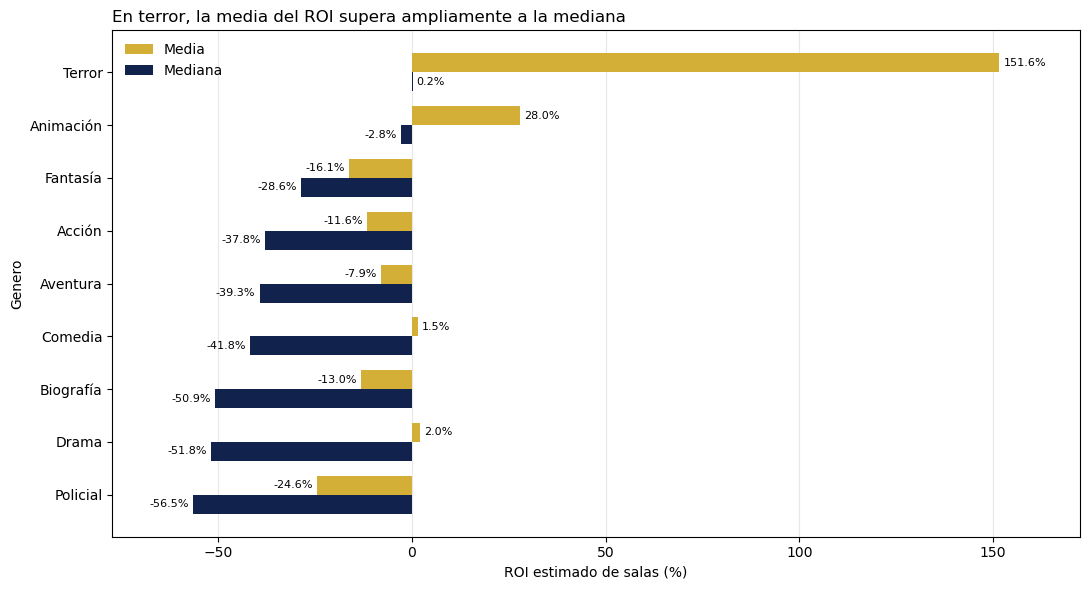

Generos mostrados: 9 | minimo por genero: 30


In [277]:
# Comparamos media y mediana solo en generos con suficiente muestra.
ANCHO_BARRA = 0.36
MARGEN_EJE_PCT = 0.10
generos_comparacion = resumen_genero.loc[
    resumen_genero.peliculas >= MIN_PELICULAS_COMPARABLES].sort_values(
        'roi_mediano_pct')
posiciones = np.arange(len(generos_comparacion))

fig, ax = plt.subplots(figsize=(11, 6))
barras_media = ax.barh(
    posiciones + ANCHO_BARRA / 2, generos_comparacion.roi_medio_pct,
    height=ANCHO_BARRA, color=DORADO_GRAFICO, label='Media')
barras_mediana = ax.barh(
    posiciones - ANCHO_BARRA / 2, generos_comparacion.roi_mediano_pct,
    height=ANCHO_BARRA, color=AZUL_GRAFICO, label='Mediana')

ax.set_yticks(posiciones)
ax.set_yticklabels(generos_comparacion.genero)
roi_min = min(generos_comparacion.roi_medio_pct.min(),
              generos_comparacion.roi_mediano_pct.min())
roi_max = max(generos_comparacion.roi_medio_pct.max(),
              generos_comparacion.roi_mediano_pct.max())
margen_eje = (roi_max - roi_min) * MARGEN_EJE_PCT
ax.set_xlim(roi_min - margen_eje, roi_max + margen_eje)
ax.bar_label(barras_media, fmt='%.1f%%', padding=3, fontsize=8)
ax.bar_label(barras_mediana, fmt='%.1f%%', padding=3, fontsize=8)
ax.set_title('En terror, la media del ROI supera ampliamente a la mediana',
             loc='left')
ax.set_xlabel('ROI estimado de salas (%)')
ax.set_ylabel('Genero')
ax.legend(frameon=False)
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(carpeta_salidas / '38_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

print('Generos mostrados:', len(generos_comparacion),
      '| minimo por genero:', MIN_PELICULAS_COMPARABLES)

### Películas que elevan el promedio

In [278]:
# Elegimos las tres mayores brechas entre generos con al menos 30 peliculas.
generos_brecha = (resumen_genero.loc[
    resumen_genero.peliculas >= MIN_PELICULAS_COMPARABLES]
    .nlargest(3, 'diferencia_pp'))
filas_impacto = []
peliculas_extremas = []
for genero_brecha in generos_brecha.genero:
    grupo_brecha = universo_negocio.loc[
        universo_negocio.genero == genero_brecha]
    dos_mayores = grupo_brecha.nlargest(2, 'roi_pct')
    filas_impacto.append({
        'genero': genero_brecha,
        'peliculas': len(grupo_brecha),
        'media_original_pct': grupo_brecha.roi_pct.mean(),
        'media_sin_dos_pct': grupo_brecha.drop(dos_mayores.index).roi_pct.mean(),
        'mediana_pct': grupo_brecha.roi_pct.median(),
    })
    peliculas_extremas.append(dos_mayores[
        ['genero', 'titulo', 'anio_estreno', 'presupuesto_usd',
         'recaudacion_mundial_usd', 'roi_pct']])

print('Efecto de apartar los dos ROI mas altos de cada genero (solo diagnostico):')
display(pd.DataFrame(filas_impacto).round(1))
print('Peliculas responsables de esos valores extremos:')
display(pd.concat(peliculas_extremas).round(1))

Efecto de apartar los dos ROI mas altos de cada genero (solo diagnostico):


,genero,peliculas,media_original_pct,media_sin_dos_pct,mediana_pct
0,Terror,236,151.6,126.9,0.2
1,Drama,829,2.0,-0.8,-51.8
2,Comedia,1408,1.5,-1.8,-41.8


Peliculas responsables de esos valores extremos:


,genero,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd,roi_pct
7312,Terror,The Devil Inside,2012,1000000.0,101758490.0,3291.9
990,Terror,Saw,2004,1200000.0,103911669.0,2786.4
3475,Drama,The Lives of Others,2006,2000000.0,77356942.0,1189.3
166,Drama,Dirty Dancing,1987,6000000.0,214577242.0,1092.1
5548,Comedia,My Big Fat Greek Wedding,2002,5000000.0,368744044.0,2358.3
1302,Comedia,The Full Monty,1997,3500000.0,257938649.0,2356.6


Apartamos temporalmente el 10% de mayor ROI de cada género para medir su efecto sobre la media. Es una prueba de sensibilidad: esas películas permanecen en el análisis principal.

In [279]:
filas_cola = []
for genero_brecha in generos_brecha.genero:
    grupo_brecha = universo_negocio.loc[
        universo_negocio.genero == genero_brecha]
    cantidad_decil = int(np.ceil(len(grupo_brecha) * 0.10))
    decil_superior = grupo_brecha.nlargest(cantidad_decil, 'roi_pct')
    filas_cola.append({
        'genero': genero_brecha,
        'peliculas_apartadas': cantidad_decil,
        'media_original_pct': grupo_brecha.roi_pct.mean(),
        'media_sin_top_10_pct': grupo_brecha.drop(decil_superior.index).roi_pct.mean(),
        'mediana_pct': grupo_brecha.roi_pct.median(),
    })
display(pd.DataFrame(filas_cola).round(1))

,genero,peliculas_apartadas,media_original_pct,media_sin_top_10_pct,mediana_pct
0,Terror,24,151.6,31.3,0.2
1,Drama,83,2.0,-40.2,-51.8
2,Comedia,141,1.5,-35.3,-41.8


- **Media frente a mediana:** terror registra 151,6% frente a 0,2%; drama, 2,0% frente a −51,8%; comedia, 1,5% frente a −41,8%. La película típica rinde menos que el promedio.
- **Efecto de los éxitos:** sin el 10% de mayor ROI, solo como prueba, las medias bajan a 31,3% en terror, −40,2% en drama y −35,3% en comedia.
- **¿Error o realidad?** Los presupuestos de los casos destacados coinciden con fuentes de taquilla: terror ([*The Devil Inside*](https://www.the-numbers.com/movie/Devil-Inside-The), [*Saw*](https://www.the-numbers.com/movie/Saw-%282004%29)), drama ([*The Lives of Others*](https://www.the-numbers.com/movie/Leben-der-Anderen-Das), [*Dirty Dancing*](https://www.boxofficemojo.com/title/tt0092890/)) y comedia ([*My Big Fat Greek Wedding*](https://www.the-numbers.com/movie/My-Big-Fat-Greek-Wedding), [*The Full Monty*](https://www.the-numbers.com/movie/Full-Monty-The)). En estos ejemplos no aparece un error de escala ×1.000; son éxitos reales que elevan la media.

In [280]:
print('Peliculas con mayor ROI en el universo principal:')
display(universo_negocio.sort_values('roi_salas_estimado', ascending=False)
        [['titulo','genero','presupuesto_usd',
          'recaudacion_mundial_usd','roi_pct']].head(8).round(1))

# Contrastamos importes pequenos: un multiplo enorme no prueba un error.
casos_a_revisar = datos.loc[datos.titulo.isin(
    ['Platoon','Paranormal Activity','The Devil Inside']),
    ['titulo','anio_estreno','presupuesto_usd',
     'recaudacion_mundial_usd','multiplo_boleteria','escala_dudosa']]
print('Casos que ayudan a distinguir errores de exitos reales:')
display(casos_a_revisar.round(1))

Peliculas con mayor ROI en el universo principal:


,titulo,genero,presupuesto_usd,recaudacion_mundial_usd,roi_pct
7312,The Devil Inside,Terror,1000000.0,101758490.0,3291.9
990,Saw,Terror,1200000.0,103911669.0,2786.4
7397,E.T. the Extra-Terrestrial,Familiar,10500000.0,792910554.0,2417.2
5548,My Big Fat Greek Wedding,Comedia,5000000.0,368744044.0,2358.3
1302,The Full Monty,Comedia,3500000.0,257938649.0,2356.6
2217,Insidious,Terror,1500000.0,99557032.0,2112.4
4566,Unfriended,Terror,1000000.0,62882090.0,1996.1
217,Paranormal Activity 2,Terror,3000000.0,177512032.0,1872.4


Casos que ayudan a distinguir errores de exitos reales:


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd,multiplo_boleteria,escala_dudosa
263,Platoon,1986,6000.0,138545632.0,23090.9,True
5886,Paranormal Activity,2007,15000.0,193355800.0,12890.4,True
7312,The Devil Inside,2012,1000000.0,101758490.0,101.8,False


- **Error fuera del universo principal:** *Platoon* figura con USD 6.000 en la base, frente a [USD 6 millones publicados](https://www.the-numbers.com/movie/Platoon); el filtro la excluye.
- **Presupuesto mínimo real:** [Paramount informa USD 15.000](https://ir.paramount.com/news-releases/news-release-details/paramount-pictures-paranormal-activity-soars-past-100-million/) para *Paranormal Activity*, también excluida por el filtro.
- **Éxito dentro del universo:** *The Devil Inside* figura con USD 1 millón, de acuerdo con [su presupuesto publicado](https://www.the-numbers.com/movie/Devil-Inside-The). Un ROI muy alto no prueba por sí solo un error de carga.

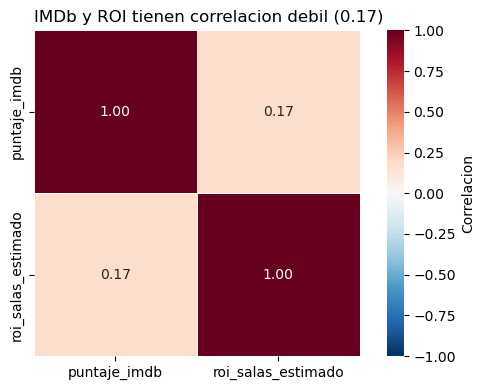

Peliculas con puntaje IMDb y ROI: 5198
Correlacion IMDb–ROI: 0.173


In [281]:
# Correlacion de Pearson en el mismo universo usado para comparar retornos.
variables_correlacion = ['puntaje_imdb','roi_salas_estimado']
matriz_correlacion = universo_negocio[variables_correlacion].corr()
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(matriz_correlacion, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True,
            cbar_kws={'label':'Correlacion'}, ax=ax)
correlacion_imdb_roi = matriz_correlacion.loc[
    'puntaje_imdb','roi_salas_estimado']
ax.set_title(f'IMDb y ROI tienen correlacion debil ({correlacion_imdb_roi:.2f})',
             loc='left')
fig.tight_layout()
fig.savefig(carpeta_salidas / '42_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

print('Peliculas con puntaje IMDb y ROI:',
      universo_negocio[variables_correlacion].dropna().shape[0])
print('Correlacion IMDb–ROI:', round(correlacion_imdb_roi, 3))

La relacion entre IMDb y retorno es debil. Una buena puntuacion no asegura recuperar la inversion.

Ademas, el puntaje se conoce despues del estreno. No lo podemos usar para elegir que pelicula financiar antes de hacerla.


## 3.3 ¿Donde esta el riesgo?


In [282]:
FRACCION_PEOR_DECIL = 0.10

def retorno_peor_decil(serie):
    limite = serie.quantile(FRACCION_PEOR_DECIL)
    return serie.loc[serie <= limite].mean()

def tabla_riesgo(columna):
    tabla = universo_negocio.groupby(columna).agg(
        peliculas=('id_pelicula','size'),
        roi_mediano_pct=('roi_pct','median'),
        fracaso_pct=('fracaso_2_5x','mean'),
        perdida_roi_pct=('perdida_roi','mean'),
        roi_peor_decil_pct=('roi_pct',retorno_peor_decil)).reset_index()
    tabla['fracaso_pct'] = 100 * tabla.fracaso_pct
    tabla['perdida_roi_pct'] *= 100
    return tabla.sort_values('peliculas', ascending=False)

riesgo_genero = tabla_riesgo('genero')
riesgo_secuela = tabla_riesgo('es_secuela')
print('Riesgo por genero: fracaso_pct = no llegar a 2,5×; perdida_roi_pct = ROI negativo')
display(riesgo_genero.round(1))
print('Riesgo por franquicia: fracaso_pct = no llegar a 2,5×; perdida_roi_pct = ROI negativo')
display(riesgo_secuela.round(1))

# Aplicamos el mismo criterio de dominancia a las dos categorias de franquicia.
secuela_si = riesgo_secuela.loc[
    riesgo_secuela.es_secuela == 'Si'].iloc[0]
secuela_no = riesgo_secuela.loc[
    riesgo_secuela.es_secuela == 'No'].iloc[0]
print('Dominancia por franquicia:')
if (secuela_si.roi_mediano_pct > secuela_no.roi_mediano_pct
        and secuela_si.fracaso_pct < secuela_no.fracaso_pct):
    print('Las secuelas dominan en ROI mediano y en no llegar a 2,5×.')
else:
    print('No hay dominancia de secuelas en ROI mediano y regla de 2,5×.')

# Dominancia compara mediana y fracaso; la propia fila no se domina a si misma.
comparables = riesgo_genero.loc[
    riesgo_genero.peliculas >= MIN_PELICULAS_COMPARABLES].reset_index(drop=True).copy()
dominador_ejemplo = []
for i in range(len(comparables)):
    actual = comparables.iloc[i]
    mejor_retorno = comparables.roi_mediano_pct >= actual.roi_mediano_pct
    menor_fracaso = comparables.fracaso_pct <= actual.fracaso_pct
    ventaja_estricta = ((comparables.roi_mediano_pct > actual.roi_mediano_pct)
                        | (comparables.fracaso_pct < actual.fracaso_pct))
    nombres = comparables.loc[mejor_retorno & menor_fracaso & ventaja_estricta,
                             'genero']
    if len(nombres) > 0:
        dominador_ejemplo.append(nombres.iloc[0])
    else:
        dominador_ejemplo.append('Ninguno')

comparables['dominador_ejemplo'] = dominador_ejemplo
print('Dominancia entre generos con al menos', MIN_PELICULAS_COMPARABLES,
      'peliculas:')
display(comparables.sort_values('roi_mediano_pct', ascending=False)
        [['genero','peliculas','roi_mediano_pct','fracaso_pct',
          'roi_peor_decil_pct','dominador_ejemplo']].round(1))
print('Generos no dominados:',
      ', '.join(list(comparables.loc[
          comparables.dominador_ejemplo == 'Ninguno', 'genero'])))

Riesgo por genero: fracaso_pct = no llegar a 2,5×; perdida_roi_pct = ROI negativo


,genero,peliculas,roi_mediano_pct,fracaso_pct,perdida_roi_pct,roi_peor_decil_pct
5,Comedia,1408,-41.8,62.9,70.3,-95.7
0,Acción,1378,-37.8,62.8,69.8,-93.2
6,Drama,829,-51.8,65.0,71.2,-98.0
10,Policial,385,-56.5,71.2,76.6,-97.3
2,Aventura,317,-39.3,61.5,69.4,-96.3
3,Biografía,307,-50.9,68.4,74.9,-95.6
1,Animación,272,-2.8,41.9,51.8,-89.1
13,Terror,236,0.2,42.8,50.0,-92.8
8,Fantasía,42,-28.6,57.1,66.7,-96.1
9,Misterio,17,-34.1,58.8,58.8,-99.3


Riesgo por franquicia: fracaso_pct = no llegar a 2,5×; perdida_roi_pct = ROI negativo


,es_secuela,peliculas,roi_mediano_pct,fracaso_pct,perdida_roi_pct,roi_peor_decil_pct
0,No,4653,-44.6,64.5,71.3,-96.2
1,Si,562,-1.5,41.1,50.2,-86.6


Dominancia por franquicia:
Las secuelas dominan en ROI mediano y en no llegar a 2,5×.
Dominancia entre generos con al menos 30 peliculas:


,genero,peliculas,roi_mediano_pct,fracaso_pct,roi_peor_decil_pct,dominador_ejemplo
7,Terror,236,0.2,42.8,-92.8,Ninguno
6,Animación,272,-2.8,41.9,-89.1,Ninguno
8,Fantasía,42,-28.6,57.1,-96.1,Animación
1,Acción,1378,-37.8,62.8,-93.2,Animación
4,Aventura,317,-39.3,61.5,-96.3,Animación
0,Comedia,1408,-41.8,62.9,-95.7,Acción
5,Biografía,307,-50.9,68.4,-95.6,Comedia
2,Drama,829,-51.8,65.0,-98.0,Comedia
3,Policial,385,-56.5,71.2,-97.3,Comedia


Generos no dominados: Animación, Terror


### Riesgo y retorno mediano por género

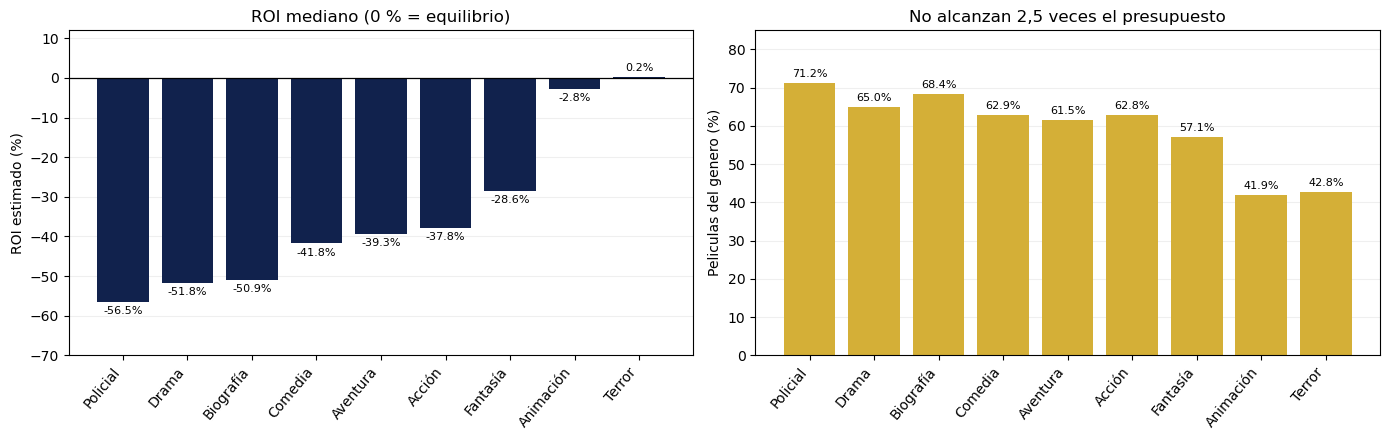

In [283]:
# Mismos generos comparables usados en la tabla de dominancia.
riesgo_barras = comparables.sort_values('roi_mediano_pct').reset_index(drop=True)
posiciones_riesgo = np.arange(len(riesgo_barras))
etiquetas_riesgo = riesgo_barras.genero.tolist()

fig, (ax_retorno, ax_fracaso) = plt.subplots(
    1, 2, figsize=(14, 4.5))
barras_retorno = ax_retorno.bar(
    posiciones_riesgo, riesgo_barras.roi_mediano_pct, color=AZUL_GRAFICO)
ax_retorno.axhline(0, color='black', linewidth=0.9)
ax_retorno.set_ylim(-70, 12)
ax_retorno.bar_label(barras_retorno, fmt='%.1f%%', padding=3, fontsize=8)
ax_retorno.set_title('ROI mediano (0 % = equilibrio)')
ax_retorno.set_ylabel('ROI estimado (%)')

barras_fracaso = ax_fracaso.bar(
    posiciones_riesgo, riesgo_barras.fracaso_pct, color=DORADO_GRAFICO)
ax_fracaso.set_ylim(0, 85)
ax_fracaso.bar_label(barras_fracaso, fmt='%.1f%%', padding=3, fontsize=8)
ax_fracaso.set_title('No alcanzan 2,5 veces el presupuesto')
ax_fracaso.set_ylabel('Peliculas del genero (%)')

for eje in (ax_retorno, ax_fracaso):
    eje.set_xticks(posiciones_riesgo, etiquetas_riesgo, rotation=50, ha='right')
    eje.grid(axis='y', alpha=0.2)
    eje.set_axisbelow(True)

fig.tight_layout()
fig.savefig(carpeta_salidas / '3_3_riesgo_por_genero.png',
            dpi=150, bbox_inches='tight')
plt.show()

- **Gráficos:** el eje horizontal muestra los géneros con al menos 30 películas (sus tamaños están en la tabla anterior). A la izquierda, las barras bajo 0% indican ROI mediano negativo; a la derecha, barras más altas indican que más películas no llegan a 2,5×.
- `fracaso_pct` es el porcentaje que **no llega a 2,5×**; `perdida_roi_pct` es el porcentaje con **ROI negativo**. Son los dos indicadores creados en 2.3 y pueden dar cifras distintas.
- `roi_peor_decil_pct` es el ROI promedio del 10% con peor resultado. Un género domina a otro si tiene a la vez mayor ROI mediano y menos películas bajo 2,5×.
- **Géneros:** terror tiene ROI mediano de 0,2% y 42,8% de películas bajo 2,5×. Animación tiene −2,8% y 41,9%. Terror gana un poco en retorno y animación un poco en riesgo: ninguno supera al otro en ambas medidas.
- **Franquicias:** las secuelas tienen mejor ROI mediano y menos casos bajo 2,5× que las no secuelas. Aun así, su ROI mediano es −1,5%; no equivale a una ganancia asegurada.
- **Cuánto se puede perder:** entre el 10% de peores películas, el ROI promedio es −92,8% en terror y −89,1% en animación. Incluso los grupos mejor posicionados pueden perder casi todo el costo estimado en algunos proyectos; por eso conviene diversificar.

## 4.1 Evolucion nominal y real de la recaudacion


In [284]:
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

pio.templates.default = 'plotly_white'
GRIS_GRAFICO = '#BBBBBB'

figura_evolucion = go.Figure()
figura_evolucion.add_trace(go.Scatter(
    x=serie_regular.anio_estreno, y=serie_regular.nominal_millones,
    mode='lines', name='Dolares corrientes',
    line={'color':AZUL_GRAFICO,'width':2}))
figura_evolucion.add_trace(go.Scatter(
    x=serie_regular.anio_estreno, y=serie_regular.real_millones,
    mode='lines', name='Dolares de 2020',
    line={'color':DORADO_GRAFICO,'width':2}))
figura_evolucion.update_layout(
    title='La recaudacion nominal y real muestran trayectorias distintas',
    xaxis_title='Año de estreno',
    yaxis_title='Recaudacion mediana por pelicula (USD millones)',
    hovermode='x unified', height=460)
figura_evolucion.update_yaxes(rangemode='tozero')
figura_evolucion.write_html(carpeta_salidas / 'evolucion_interactiva.html', include_plotlyjs='cdn')
figura_evolucion.show()

print('Años mostrados:', len(serie_regular),
      '| desde', serie_regular.anio_estreno.min(),
      'hasta', serie_regular.anio_estreno.max())

Años mostrados: 35 | desde 1985 hasta 2019


La serie nominal sugiere crecimiento sostenido. En dólares de 2020, la mediana sube hasta los 2000 y baja en los 2010; por eso no conviene interpretar el aumento nominal como crecimiento real continuo.

## 4.2 Distribución del múltiplo de boletería


In [285]:
ROI_TOPE_VISUAL_PCT = 300
CANTIDAD_BINS_ROI = 40

roi_visual = universo_negocio[['roi_pct']].copy()
roi_visual['roi_grafico_pct'] = roi_visual.roi_pct.clip(
    upper=ROI_TOPE_VISUAL_PCT)
media_roi = roi_visual.roi_pct.mean()
mediana_roi = roi_visual.roi_pct.median()

# Agrupamos el ROI en intervalos para mostrar cantidad y rango al pasar el cursor.
conteos_roi, bordes_roi = np.histogram(
    roi_visual.roi_grafico_pct.astype(float),
    bins=CANTIDAD_BINS_ROI, range=(-100, ROI_TOPE_VISUAL_PCT))
centros_roi = (bordes_roi[:-1] + bordes_roi[1:]) / 2
intervalos_roi = [
    f'{inicio:.0f}% a {fin:.0f}%'
    for inicio, fin in zip(bordes_roi[:-1], bordes_roi[1:])
]
intervalos_roi[-1] = '290% o mas (incluye ROI mayores a 300%)'

figura_roi = go.Figure(go.Bar(
    x=centros_roi, y=conteos_roi, width=9.5,
    customdata=intervalos_roi, marker_color=AZUL_CLARO_GRAFICO,
    hovertemplate='ROI: %{customdata}<br>Peliculas: %{y}<extra></extra>'))
figura_roi.add_vline(
    x=mediana_roi, line_color=AZUL_GRAFICO, line_width=2.5,
    annotation_text=f'Mediana: {mediana_roi:.1f}%')
figura_roi.add_vline(
    x=media_roi, line_color=DORADO_GRAFICO, line_width=2.5,
    line_dash='dash', annotation_text=f'Media: {media_roi:.1f}%')
figura_roi.update_layout(
    title='La media positiva esconde perdidas en la mayoria',
    xaxis_title='ROI estimado de salas (%)',
    yaxis_title='Numero de peliculas',
    height=450, bargap=0.03, margin={'t':110},
    updatemenus=[{'type':'buttons', 'direction':'right',
        'x':1, 'xanchor':'right', 'y':1.22, 'showactive':True,
        'buttons':[
            {'label':'Conteo lineal', 'method':'relayout',
             'args':[{'yaxis.type':'linear',
                      'yaxis.title':'Numero de peliculas'}]},
            {'label':'Conteo logaritmico', 'method':'relayout',
             'args':[{'yaxis.type':'log',
                      'yaxis.title':'Numero de peliculas (escala log)'}]}
        ]}])
figura_roi.write_html(carpeta_salidas / 'roi_interactivo.html',
                      include_plotlyjs='cdn')
figura_roi.show()

print('Peliculas mostradas:', len(roi_visual))
print('Peliculas con ROI estimado negativo:',
      (roi_visual.roi_pct < 0).sum(),
      f'({(roi_visual.roi_pct < 0).mean():.1%})')
print('ROI mayores que', ROI_TOPE_VISUAL_PCT, '% agrupados visualmente:',
      (roi_visual.roi_pct > ROI_TOPE_VISUAL_PCT).sum())
print('ROI medio y mediano (%):',
      round(media_roi, 1), 'y', round(mediana_roi, 1))

Peliculas mostradas: 5215
Peliculas con ROI estimado negativo: 3600 (69.0%)
ROI mayores que 300 % agrupados visualmente: 174
ROI medio y mediano (%): 3.2 y -39.9


- **Histograma:** el eje horizontal muestra cuántas veces la recaudación supera el presupuesto, en escala logarítmica. El eje vertical mantiene la **cantidad de películas en escala lineal**. Las líneas señalan mediana, promedio y umbral de 2,5 veces.
- **Boxplot:** cada caja muestra la parte central de los múltiplos de un género; la línea dentro es la mediana, el rombo es el promedio y los puntos son valores extremos. Los géneros con menos de 30 películas se reúnen en «Otros».
- **Lectura:** el múltiplo solo puede mostrarse en escala logarítmica si es positivo; los casos con múltiplo cero se excluyen del gráfico y se cuentan debajo. El ROI estimado sigue calculándose con todos los datos del universo principal.

## 4.3 Retorno mediano por genero


In [286]:
generos_grafico = comparables.sort_values('roi_mediano_pct')

figura_generos = px.bar(
    generos_grafico, x='roi_mediano_pct', y='genero',
    orientation='h', text='roi_mediano_pct',
    hover_data=['peliculas','fracaso_pct','roi_peor_decil_pct'],
    color_discrete_sequence=[AZUL_GRAFICO],
    labels={'roi_mediano_pct':'ROI mediano estimado (%)',
            'genero':'Genero',
            'peliculas':'Peliculas',
            'fracaso_pct':'Fracaso segun 2,5× (%)',
            'roi_peor_decil_pct':'ROI medio del peor decil (%)'},
    title='Terror y animacion encabezan el ROI mediano entre generos comparables')
figura_generos.update_traces(texttemplate='%{text:.1f}%',
                             textposition='outside', cliponaxis=False)
limite_izquierdo = min(-60, generos_grafico.roi_mediano_pct.min() - 7)
limite_derecho = max(5, generos_grafico.roi_mediano_pct.max() + 5)
figura_generos.update_xaxes(range=[limite_izquierdo, limite_derecho])
figura_generos.update_layout(height=530,
                             margin={'l':145,'r':90,'t':80,'b':60})
figura_generos.write_html(carpeta_salidas / 'generos_interactivo.html', include_plotlyjs='cdn')
figura_generos.show()

print('Generos mostrados:', len(generos_grafico),
      '| minimo por genero:', MIN_PELICULAS_COMPARABLES)

Generos mostrados: 9 | minimo por genero: 30


Terror y animacion quedan entre los generos con mejor retorno mediano. Esto no significa que sean seguros: tambien tienen peliculas con perdidas. En el grafico se puede consultar cuantos casos tiene cada grupo.


## 4.4 Presupuesto frente a recaudacion


In [287]:
# La escala logaritmica requiere importes estrictamente positivos.
dispersion = universo_negocio.loc[
    (universo_negocio.presupuesto_2020_usd > 0)
    & (universo_negocio.recaudacion_2020_usd > 0)].copy()
dispersion['presupuesto_millones'] = (
    dispersion.presupuesto_2020_usd / USD_POR_MILLON)
dispersion['recaudacion_millones'] = (
    dispersion.recaudacion_2020_usd / USD_POR_MILLON)

dispersion['resultado_2_5x'] = dispersion.fracaso_2_5x.map({
    True:'Debajo de 2,5×', False:'Al menos 2,5×'})
figura_dispersion = px.scatter(
    dispersion, x='presupuesto_millones', y='recaudacion_millones',
    color='resultado_2_5x', hover_name='titulo',
    hover_data={'anio_estreno':True, 'genero':True,
                'presupuesto_millones':':.2f',
                'recaudacion_millones':':.2f',
                'multiplo_boleteria':':.1f',
                'resultado_2_5x':False},
    color_discrete_map={'Debajo de 2,5×':GRIS_GRAFICO,
                        'Al menos 2,5×':AZUL_GRAFICO},
    opacity=0.4, log_x=True, log_y=True,
    labels={'presupuesto_millones':'Presupuesto (USD millones de 2020)',
            'recaudacion_millones':'Recaudacion mundial (USD millones de 2020)',
            'multiplo_boleteria':'Recaudacion / presupuesto'},
    title='Presupuestos similares tienen recaudaciones muy distintas')
presupuesto_min = dispersion.presupuesto_millones.min()
presupuesto_max = dispersion.presupuesto_millones.max()
figura_dispersion.add_trace(go.Scatter(
    x=[presupuesto_min, presupuesto_max],
    y=[UMBRAL_RECUPERO * presupuesto_min,
       UMBRAL_RECUPERO * presupuesto_max],
    mode='lines', name='Umbral de 2,5×',
    line={'color':DORADO_GRAFICO, 'dash':'dash', 'width':2},
    hovertemplate='Recaudacion = 2,5 × presupuesto<extra></extra>'))
figura_dispersion.update_layout(
    height=520, legend_title_text='Regla de 2,5×',
    margin={'l':80, 'r':70, 't':80, 'b':70})
figura_dispersion.write_html(
    carpeta_salidas / 'presupuesto_recaudacion_interactivo.html',
    include_plotlyjs='cdn')
figura_dispersion.show()

print('Peliculas mostradas:', len(dispersion),
      '| excluidas por importe cero para la escala log:',
      len(universo_negocio) - len(dispersion))

Peliculas mostradas: 5215 | excluidas por importe cero para la escala log: 0


Películas con presupuestos parecidos tienen recaudaciones muy distintas. El gráfico interactivo permite ver cada título y sus importes; ambos ejes usan escala logarítmica para comparar montos muy diferentes. La línea marca 2,5 veces el presupuesto y los colores usan `fracaso_2_5x` de 2.3. Estar por encima cumple esa regla, pero no garantiza ROI positivo con los costos supuestos.

# Etapa 5: propuesta de inversion

## 5.1 Definir los grupos

In [288]:
CORTES_PRESUPUESTO_M = [0, 10, 30, 70, np.inf]
NOMBRES_TRAMOS = ['Hasta 10', '10-30', '30-70', 'Mas de 70']

portafolio_base = universo_negocio.copy()
portafolio_base['presupuesto_millones'] = (
    portafolio_base.presupuesto_2020_usd / USD_POR_MILLON)
portafolio_base['tramo_presupuesto'] = pd.cut(
    portafolio_base.presupuesto_millones,
    bins=CORTES_PRESUPUESTO_M, labels=NOMBRES_TRAMOS)

# Verificamos que los tramos propuestos tengan casos suficientes.
resumen_tramos = portafolio_base.groupby(
    'tramo_presupuesto', observed=True).agg(
        peliculas=('id_pelicula','size'),
        presupuesto_mediano_m=('presupuesto_millones','median')).reset_index()
print('Peliculas y presupuesto mediano por tramo:')
display(resumen_tramos.round(1))

# Cada fila define un grupo observable; la asignacion se decide en 5.2.
grupos_elegidos = pd.DataFrame([
    {'grupo':'Animacion, mas de 70 M, secuela',
     'genero':'Animación', 'tramo':'Mas de 70', 'es_secuela':'Si'},
    {'grupo':'Accion, 30-70 M, secuela',
     'genero':'Acción', 'tramo':'30-70', 'es_secuela':'Si'},
    {'grupo':'Comedia, 30-70 M, secuela',
     'genero':'Comedia', 'tramo':'30-70', 'es_secuela':'Si'},
    {'grupo':'Terror, hasta 10 M, no secuela',
     'genero':'Terror', 'tramo':'Hasta 10', 'es_secuela':'No'}
])

filas_grupos = []
retornos_historicos = {}
for i in range(len(grupos_elegidos)):
    criterio = grupos_elegidos.iloc[i]
    historicas = portafolio_base.loc[
        (portafolio_base.genero == criterio['genero'])
        & (portafolio_base.tramo_presupuesto == criterio['tramo'])
        & (portafolio_base.es_secuela == criterio['es_secuela'])]
    retornos_historicos[criterio['grupo']] = (
        historicas.roi_salas_estimado.values)
    filas_grupos.append({
        'grupo':criterio['grupo'],
        'peliculas_historicas':len(historicas),
        'presupuesto_mediano_m':historicas.presupuesto_millones.median(),
        'roi_mediano_pct':100 * historicas.roi_salas_estimado.median(),
        'perdida_roi_pct':100 * historicas.perdida_roi.mean(),
        'fracaso_pct':100 * historicas.fracaso_2_5x.mean()
    })

resumen_grupos = pd.DataFrame(filas_grupos)
print('Cuatro grupos propuestos; presupuestos en USD millones de 2020:')
display(resumen_grupos.round(1))
print('Minimo de peliculas historicas por grupo:',
      resumen_grupos.peliculas_historicas.min())

# Comparamos los grupos intermedios con peliculas no secuela equivalentes.
comparadores = portafolio_base.loc[
    portafolio_base.genero.isin(['Acción', 'Comedia'])
    & (portafolio_base.tramo_presupuesto == '30-70')]
comparacion_secuela = comparadores.groupby(
    ['genero', 'es_secuela']).agg(
        peliculas=('id_pelicula', 'size'),
        roi_mediano_pct=('roi_salas_estimado', 'median'),
        fracaso_pct=('fracaso_2_5x', 'mean')).reset_index()
comparacion_secuela['roi_mediano_pct'] = (
    100 * comparacion_secuela.roi_mediano_pct)
comparacion_secuela['fracaso_pct'] = (
    100 * comparacion_secuela.fracaso_pct)
print('Accion y comedia de 30–70 M: secuelas frente a no secuelas:')
display(comparacion_secuela.round(1))

Peliculas y presupuesto mediano por tramo:


,tramo_presupuesto,peliculas,presupuesto_mediano_m
0,Hasta 10,685,5.7
1,10-30,1612,19.3
2,30-70,1725,43.6
3,Mas de 70,1193,109.2


Cuatro grupos propuestos; presupuestos en USD millones de 2020:


,grupo,peliculas_historicas,presupuesto_mediano_m,roi_mediano_pct,perdida_roi_pct,fracaso_pct
0,"Animacion, mas de 70 M, secuela",42,112.9,41.0,31.0,26.2
1,"Accion, 30-70 M, secuela",80,47.9,-8.6,53.8,46.2
2,"Comedia, 30-70 M, secuela",33,43.8,-4.0,51.5,36.4
3,"Terror, hasta 10 M, no secuela",66,5.2,44.6,40.9,37.9


Minimo de peliculas historicas por grupo: 33
Accion y comedia de 30–70 M: secuelas frente a no secuelas:


,genero,es_secuela,peliculas,roi_mediano_pct,fracaso_pct
0,Acción,No,399,-51.7,71.9
1,Acción,Si,80,-8.6,46.2
2,Comedia,No,467,-47.7,66.0
3,Comedia,Si,33,-4.0,36.4


Elegimos cuatro grupos según género, presupuesto y si son secuelas. Los cortes separan proyectos chicos, medianos y grandes dentro del universo principal. El grupo «Terror, hasta 10 M» no incluye películas con presupuesto nominal menor a USD 1 millón, aunque su nombre diga «hasta 10 M».

En la tabla, `fracaso_pct` indica no llegar a 2,5× y `perdida_roi_pct` indica ROI negativo; ambos vienen de 2.3.

Animacion y terror tienen medianas positivas. Accion y comedia secuela de presupuesto medio tienen medianas algo negativas, pero mejores que las no secuelas del mismo tramo. Las incluimos con una participacion limitada.


## 5.2 Distribuir los USD 500 millones

In [289]:
CAPITAL_TOTAL_M = 500
FACTOR_COSTO_TOTAL = 1 + MARKETING_SOBRE_PRESUPUESTO

asignacion = pd.DataFrame([
    {'grupo':'Animacion, mas de 70 M, secuela', 'asignacion_m':170, 'proyectos':1},
    {'grupo':'Accion, 30-70 M, secuela', 'asignacion_m':144, 'proyectos':2},
    {'grupo':'Comedia, 30-70 M, secuela', 'asignacion_m':66, 'proyectos':1},
    {'grupo':'Terror, hasta 10 M, no secuela', 'asignacion_m':120, 'proyectos':15}
])
propuesta = resumen_grupos.merge(asignacion, on='grupo')
propuesta['capital_por_proyecto_m'] = propuesta.asignacion_m / propuesta.proyectos
propuesta['produccion_por_proyecto_m'] = propuesta.capital_por_proyecto_m / FACTOR_COSTO_TOTAL
propuesta['marketing_por_proyecto_m'] = (
    propuesta.produccion_por_proyecto_m * MARKETING_SOBRE_PRESUPUESTO)
propuesta['diferencia_vs_mediana_pct'] = (
    propuesta.produccion_por_proyecto_m / propuesta.presupuesto_mediano_m - 1) * 100
propuesta['participacion_pct'] = propuesta.asignacion_m / CAPITAL_TOTAL_M * 100
print('¿La asignacion suma 500 millones?', propuesta['asignacion_m'].sum() == CAPITAL_TOTAL_M)
control_costos = (propuesta['produccion_por_proyecto_m']
                  + propuesta['marketing_por_proyecto_m']
                  - propuesta['capital_por_proyecto_m']).round(6)
print('Diferencia entre los costos y el capital por proyecto:')
display(control_costos)
display(propuesta.round(2))
print('Total asignado:', propuesta.asignacion_m.sum(), 'millones de USD')
print('Proyectos:', propuesta.proyectos.sum())


¿La asignacion suma 500 millones? True
Diferencia entre los costos y el capital por proyecto:


0    0.0
1    0.0
2    0.0
3    0.0
dtype: float64

,grupo,peliculas_historicas,presupuesto_mediano_m,roi_mediano_pct,perdida_roi_pct,fracaso_pct,asignacion_m,proyectos,capital_por_proyecto_m,produccion_por_proyecto_m,marketing_por_proyecto_m,diferencia_vs_mediana_pct,participacion_pct
0,"Animacion, mas de 70 M, secuela",42,112.92,40.99,30.95,26.19,170,1,170.0,113.33,56.67,0.37,34.0
1,"Accion, 30-70 M, secuela",80,47.88,-8.56,53.75,46.25,144,2,72.0,48.00,24.00,0.25,28.8
2,"Comedia, 30-70 M, secuela",33,43.75,-4.02,51.52,36.36,66,1,66.0,44.00,22.00,0.56,13.2
3,"Terror, hasta 10 M, no secuela",66,5.17,44.58,40.91,37.88,120,15,8.0,5.33,2.67,3.16,24.0


Total asignado: 500 millones de USD
Proyectos: 19


Los 500 millones incluyen produccion y marketing. Por eso dividimos el capital por pelicula entre 1,5 antes de compararlo con el presupuesto historico de produccion.

La propuesta suma 19 proyectos. Hay dos cosas a considerar:
- una sola pelicula de animacion recibe el 34% del dinero.
- necesitamos conseguir 15 proyectos de terror comparables en tres años.

Los montos estan en dolares de 2020. Antes de invertir habria que actualizarlos al ano correspondiente y acordar por contrato que ingresos recibe el fondo.


## 5.3 Retorno y riesgo del portafolio

In [290]:
N_SIMULACIONES = 10_000
SEMILLA_SIMULACION = 2026
retorno_central_pct = (
    (propuesta.asignacion_m * propuesta.roi_mediano_pct).sum() / CAPITAL_TOTAL_M)
print('Escenario central ponderando medianas:', f'{retorno_central_pct:.1f}%')
print('Resultado central en millones:', round(CAPITAL_TOTAL_M * retorno_central_pct / 100, 1))

generador = np.random.default_rng(SEMILLA_SIMULACION)
generador_compartido = np.random.default_rng(SEMILLA_SIMULACION + 1)
resultado_independiente_m = [0.0] * N_SIMULACIONES
resultado_compartido_m = [0.0] * N_SIMULACIONES

for i in range(len(propuesta)):
    fila = propuesta.iloc[i]
    roi_grupo = retornos_historicos[fila['grupo']]
    cantidad = int(fila['proyectos'])
    for simulacion in range(N_SIMULACIONES):
        # Sorteamos los retornos de las peliculas de este grupo.
        sorteos = generador.choice(roi_grupo, size=cantidad, replace=True)
        ganancia = fila['capital_por_proyecto_m'] * sorteos.sum()
        resultado_independiente_m[simulacion] += ganancia

    for simulacion in range(N_SIMULACIONES):
        # Aca todas las peliculas del grupo comparten el mismo resultado.
        sorteo_grupo = generador_compartido.choice(roi_grupo)
        resultado_compartido_m[simulacion] += fila['asignacion_m'] * sorteo_grupo

retornos_independientes = pd.Series(resultado_independiente_m) / CAPITAL_TOTAL_M
retornos_compartidos = pd.Series(resultado_compartido_m) / CAPITAL_TOTAL_M
filas_escenarios = []
for nombre, retornos in [('Proyectos sorteados por separado', retornos_independientes),
                         ('Resultado compartido dentro de cada grupo', retornos_compartidos)]:
    filas_escenarios.append({
        'supuesto': nombre,
        'prob_perder_capital_pct': 100 * (retornos < 0).mean(),
        'roi_decil_inferior_pct': 100 * retornos.quantile(0.10),
        'roi_mediano_pct': 100 * retornos.median()
    })
escenarios = pd.DataFrame(filas_escenarios)
display(escenarios.round(2))


Escenario central ponderando medianas: 21.6%
Resultado central en millones: 108.2


,supuesto,prob_perder_capital_pct,roi_decil_inferior_pct,roi_mediano_pct
0,Proyectos sorteados por separado,0.88,45.74,113.15
1,Resultado compartido dentro de cada grupo,23.01,-25.81,59.28


Primero ponderamos la mediana de cada grupo por el dinero que le asignamos.

Despues hacemos 10.000 sorteos de retornos historicos y contamos cuantas veces el total da negativo. Probamos tambien que las peliculas del mismo grupo compartan resultado.

La diferencia entre los escenarios muestra cuanto influye que las peliculas se muevan juntas. El percentil 10 indica el resultado por debajo del cual cae una de cada diez simulaciones, no la peor perdida posible.


## 5.4 Sensibilidad a costos y exitos extremos

In [291]:
# Reutilizamos los mismos sorteos para comparar los supuestos.
rng_sensibilidad = np.random.default_rng(2026)
resultados_sensibilidad = {}
for nombre, limite_roi, marketing in [
    ('Base: marketing 50 %', None, 0.5),
    ('ROI limitado a 1.000 %', 10, 0.5),
    ('Marketing 100 %, mismos proyectos', None, 1.0)
]:
    rng_sensibilidad = np.random.default_rng(2026)
    ingresos_m = [0.0] * N_SIMULACIONES
    costo_m = CAPITAL_TOTAL_M * (1 + marketing) / FACTOR_COSTO_TOTAL
    for i in range(len(propuesta)):
        fila = propuesta.iloc[i]
        cantidad = int(fila['proyectos'])
        for simulacion in range(N_SIMULACIONES):
            sorteos = rng_sensibilidad.choice(retornos_historicos[fila['grupo']],
                                              size=cantidad, replace=True)
            retornos = pd.Series(sorteos)
            if limite_roi is not None:
                retornos = retornos.clip(upper=limite_roi)
            ingreso = fila['capital_por_proyecto_m'] * (1 + retornos).sum()
            ingresos_m[simulacion] += ingreso
    roi_escenario = pd.Series(ingresos_m) / costo_m - 1
    resultados_sensibilidad[nombre] = {
        'capital_necesario_m': costo_m,
        'roi_mediano_pct': 100 * roi_escenario.median(),
        'prob_perder_pct': 100 * (roi_escenario < 0).mean()
    }
display(pd.DataFrame(resultados_sensibilidad).T.round(2))


,capital_necesario_m,roi_mediano_pct,prob_perder_pct
Base: marketing 50 %,500.00,113.15,0.88
ROI limitado a 1.000 %,500.00,85.45,1.32
"Marketing 100 %, mismos proyectos",666.67,59.86,6.07


Probamos que pasa si limitamos los retornos extraordinarios. Si el resultado cambia mucho, la propuesta depende de que se repitan esos exitos.

Tambien probamos marketing igual al 100% de produccion. Los mismos proyectos necesitan unos 666,7 millones, asi que no alcanzan los 500 millones. Habria que reducir la cantidad de proyectos o buscar otro financiador.


## 5.5 Donde no invertir y limitaciones

In [292]:
no_invertir = []
for genero in ['Drama', 'Policial']:
    grupo = portafolio_base.loc[
        (portafolio_base.genero == genero)
        & (portafolio_base.tramo_presupuesto == '30-70')
        & (portafolio_base.es_secuela == 'No')]
    no_invertir.append({
        'grupo':genero + ', 30-70 M, no secuela',
        'peliculas_historicas':len(grupo),
        'roi_mediano_pct':100 * grupo.roi_salas_estimado.median(),
        'fracaso_pct':100 * grupo.fracaso_2_5x.mean()
    })

print('Grupos que evitariamos inicialmente:')
display(pd.DataFrame(no_invertir).round(1))

# Movemos los cortes para ver cuanto depende de ellos la tesis.
filas_sensibilidad_cortes = []
for corte_bajo, corte_medio, corte_alto in [(8,25,65), (10,30,70),
                                             (12,35,75)]:
    terror_bajo = portafolio_base.loc[
        (portafolio_base.genero == 'Terror')
        & (portafolio_base.es_secuela == 'No')
        & (portafolio_base.presupuesto_millones <= corte_bajo)]
    accion_media = portafolio_base.loc[
        (portafolio_base.genero == 'Acción')
        & (portafolio_base.es_secuela == 'Si')
        & (portafolio_base.presupuesto_millones > corte_medio)
        & (portafolio_base.presupuesto_millones <= corte_alto)]
    filas_sensibilidad_cortes.append({
        'cortes_millones':f'{corte_bajo}/{corte_medio}/{corte_alto}',
        'terror_n':len(terror_bajo),
        'terror_roi_mediano_pct':100 * terror_bajo.roi_salas_estimado.median(),
        'accion_n':len(accion_media),
        'accion_roi_mediano_pct':100 * accion_media.roi_salas_estimado.median()
    })

print('Sensibilidad de dos grupos a los cortes de presupuesto:')
display(pd.DataFrame(filas_sensibilidad_cortes).round(1))

Grupos que evitariamos inicialmente:


,grupo,peliculas_historicas,roi_mediano_pct,fracaso_pct
0,"Drama, 30-70 M, no secuela",253,-61.6,68.4
1,"Policial, 30-70 M, no secuela",121,-60.0,75.2


Sensibilidad de dos grupos a los cortes de presupuesto:


,cortes_millones,terror_n,terror_roi_mediano_pct,accion_n,accion_roi_mediano_pct
0,8/25/65,56,80.6,73,2.4
1,10/30/70,66,44.6,80,-8.6
2,12/35/75,80,27.8,78,-11.1


No priorizaríamos drama y policial no secuela de USD 30 a 70 millones. Tienen medianas de ROI negativas y una proporción alta de películas que no llegan a 2,5×.

Limitaciones:
- faltan presupuestos y no faltan por igual en todos los grupos.
- los presupuestos de escala dudosa quedaron fuera del análisis principal; el filtro también dejó fuera películas pequeñas reales.
- elegimos usando resultados pasados, que pueden no repetirse.
- no conocemos los contratos ni los costos reales de marketing.
- no tenemos los ingresos de streaming.

Antes de invertir hay que revisar los presupuestos concretos y confirmar que existan proyectos comparables.


In [293]:
print('Propuesta final:')
display(propuesta.round(2))
print('Resultados de la simulacion:')
display(escenarios.round(2))


Propuesta final:


,grupo,peliculas_historicas,presupuesto_mediano_m,roi_mediano_pct,perdida_roi_pct,fracaso_pct,asignacion_m,proyectos,capital_por_proyecto_m,produccion_por_proyecto_m,marketing_por_proyecto_m,diferencia_vs_mediana_pct,participacion_pct
0,"Animacion, mas de 70 M, secuela",42,112.92,40.99,30.95,26.19,170,1,170.0,113.33,56.67,0.37,34.0
1,"Accion, 30-70 M, secuela",80,47.88,-8.56,53.75,46.25,144,2,72.0,48.00,24.00,0.25,28.8
2,"Comedia, 30-70 M, secuela",33,43.75,-4.02,51.52,36.36,66,1,66.0,44.00,22.00,0.56,13.2
3,"Terror, hasta 10 M, no secuela",66,5.17,44.58,40.91,37.88,120,15,8.0,5.33,2.67,3.16,24.0


Resultados de la simulacion:


,supuesto,prob_perder_capital_pct,roi_decil_inferior_pct,roi_mediano_pct
0,Proyectos sorteados por separado,0.88,45.74,113.15
1,Resultado compartido dentro de cada grupo,23.01,-25.81,59.28


Estas son las tablas finales para consultar los resultados y armar la presentacion.
